# Лабораторная работа №13: Fine-tuning diffusion model

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Подготовить изображения/captions и fixed-seed baseline.
- Выполнить SD1.5 LoRA fine-tuning.
- Сравнить checkpoints, diversity и memorization.

## Теоретическая часть

Latent diffusion добавляет шум в latent space VAE, а U-Net предсказывает noise/velocity. LoRA адаптирует attention projections без изменения всех весов. Фиксированные seeds и prompts обязательны для сравнения checkpoints.

![Архитектура latent diffusion](https://raw.githubusercontent.com/CompVis/latent-diffusion/main/assets/modelfigure.png)


Latent diffusion обучает UNet предсказывать ε в пространстве VAE. LoRA добавляет обучаемые низкоранговые поправки к attention projections; VAE, text encoder и base UNet остаются замороженными. CLIP text similarity, разнообразие и ближайшая train генерация измеряют разные свойства и требуют ручного дополнения.

Для LoRA $W^{\prime}=W+BA$, где $B\in\mathbb{R}^{d\times r}$, $A\in\mathbb{R}^{r\times k}$, $r\ll\min(d,k)$. Noise-prediction минимизирует $\mathbb{E}_{x_0,\epsilon,t}\|\epsilon-\epsilon_\theta(z_t,t,c)\|_2^2$ на VAE-latents.

## Теоретическая часть

**Диффузионные модели (Diffusion Models)** — это класс генеративных нейронных сетей, предназначенных для создания изображений путём постепенного преобразования случайного шума в осмысленное изображение. В процессе прямого распространения к исходному изображению постепенно добавляется гауссовский шум, а при обратном процессе нейронная сеть учится удалять этот шум и восстанавливать изображение.

В данной работе используется модель **Stable Diffusion 1.5**, основанная на архитектуре Latent Diffusion. В отличие от обычных диффузионных моделей, она выполняет основные вычисления не непосредственно с изображениями, а в скрытом пространстве (latent space). Для преобразования изображений в скрытое представление и обратно используется вариационный автокодировщик (VAE). Это позволяет значительно снизить вычислительные затраты.

Основным компонентом модели является **U-Net**, которая предсказывает шум, добавленный к скрытому представлению изображения. Обучение модели происходит путём минимизации ошибки между реальным шумом и предсказанным сетью значением.

Для адаптации предварительно обученной модели к новой предметной области применяется метод **LoRA (Low-Rank Adaptation)**. Его идея заключается в том, что вместо изменения всех параметров нейронной сети обучаются небольшие низкоранговые матрицы, которые добавляются к существующим весам модели:

\[
W' = W + BA
\]

где \(W\) — исходные веса модели, а \(A\) и \(B\) — обучаемые матрицы меньшего ранга. Такой подход позволяет существенно сократить количество обучаемых параметров, время обучения и требования к видеопамяти.

В лабораторной работе LoRA используется для дообучения Stable Diffusion 1.5 на наборе фотографий бабочек. При этом основные веса модели, включая VAE и текстовый энкодер, остаются замороженными, а адаптация выполняется через дополнительные обучаемые параметры.

Для оценки качества дообучения используются несколько подходов:
- **Baseline** — генерация изображений исходной моделью до обучения, необходимая для сравнения результатов.
- **CLIP similarity** — оценка соответствия сгенерированного изображения текстовому описанию.
- **Diversity** — оценка разнообразия изображений, полученных при разных случайных начальных значениях (seeds).
- **Memorization** — проверка того, насколько сильно модель воспроизводит изображения из обучающей выборки вместо создания новых вариантов.

### Экспериментальный протокол

Основной эксперимент: SD 1.5 и 28 открытых реальных фотографий бабочек Wikimedia Commons при 512 px. `download_open_data.py` скачивает файлы и для каждого проверяет метаданные CC0-1.0 через Commons API, фиксирует страницу источника, URL лицензии и SHA256. Никакие файлы студента не требуются; `CV_LORA_DATA` задаёт альтернативный каталог с той же структурой metadata.jsonl. 3 независимых адаптера по 400 optimizer updates, checkpoint на 200/400; фиксированные held-out prompts и seeds. FAST_DEV_RUN: 256 px, один update, только smoke. Требуются GPU, Pillow, pip install diffusers transformers accelerate peft safetensors torchvision; на CPU не подменять обучение имитацией. CV_ARTIFACTS указывает на постоянный каталог Drive.

### Материалы

- [Diffusers LoRA training](https://huggingface.co/docs/diffusers/training/lora)
- [Latent Diffusion](https://arxiv.org/abs/2112.10752)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.

Версии библиотек, источник данных и лицензия должны быть указаны в отчёте.

## Реализация

`FAST_DEV_RUN=True` проверяет связность пайплайна на малом бюджете и не является итоговым экспериментом. Полная сдача требует `FAST_DEV_RUN=False` и реально полученных метрик.

In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
from pathlib import Path
import os, json, random, time
import numpy as np
import torch
PROJECT_DIR = Path('/content/drive/MyDrive/lab13')
PROJECT_DIR.mkdir(parents=True, exist_ok=True)
SEED = 64
FAST_DEV_RUN = False  # True только для короткой проверки связности, не для сдачи.
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
ARTIFACTS = Path(os.environ.get('CV_ARTIFACTS', PROJECT_DIR / 'artifacts'))
ARTIFACTS.mkdir(parents=True, exist_ok=True)
DATA_ROOT = Path(os.environ.get('CV_COURSE_DATA', PROJECT_DIR / 'data'))
DATA_ROOT.mkdir(parents=True, exist_ok=True)
def save_json(name, value):
    destination = ARTIFACTS / name
    destination.parent.mkdir(parents=True, exist_ok=True)
    destination.write_text(json.dumps(value, ensure_ascii=False, indent=2))
print({'device':DEVICE,'fast_dev_run':FAST_DEV_RUN,'artifacts':str(ARTIFACTS)})

{'device': 'cuda', 'fast_dev_run': False, 'artifacts': '/content/drive/MyDrive/lab13/artifacts'}


### Лицензия и валидация изображений

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей.

**Результат.** Проверяемое состояние «Лицензия и валидация изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Проверьте физические файлы, RGB-декодирование, уникальность и лицензии подписей» и его результат доступен следующему этапу.

In [3]:
import sys, importlib
LORA_DATA = DATA_ROOT / 'lab13'
os.environ['CV_LORA_DATA'] = str(LORA_DATA)
sys.path.insert(0, str(PROJECT_DIR))
import download_open_data as dod
importlib.reload(dod)

dod.download(LORA_DATA)  # идемпотентно: уже скачанные файлы не перекачиваются

1/28 commons_00.jpg: 20230130-butterfly.jpg (135801 bytes)
2/28 commons_01.jpg: A Beautiful Black Butterfly.jpg (72201 bytes)
3/28 commons_02.jpg: A butterfly eating papaya, Location- Lakhimpur, Assam.jpg (124914 bytes)
4/28 commons_03.jpg: A butterfly on a purple flower.jpg (106346 bytes)
5/28 commons_04.jpg: Black and white butterfly near Shirahama.jpg (262645 bytes)
6/28 commons_05.jpg: Butterfly 51.jpg (90759 bytes)
7/28 commons_06.jpg: Butterfly Iguazu Falls.jpg (297914 bytes)
8/28 commons_07.jpg: Butterfly The Insect.jpg (354628 bytes)
9/28 commons_08.jpg: Butterfly at Jonanjima.jpg (93098 bytes)
10/28 commons_09.jpg: Butterfly at Wingham Wildlife Park Kent UK.jpg (84272 bytes)
11/28 commons_10.jpg: Butterfly by the water.jpg (152912 bytes)
12/28 commons_11.jpg: Butterfly enjoying with nature.jpg (101671 bytes)
13/28 commons_12.jpg: Butterfly from butterfly garden-lucknow zoo.jpg (497712 bytes)
14/28 commons_13.jpg: Butterfly hanging on leaf.jpg (163975 bytes)
15/28 commons_14.jp

[{'file_name': 'commons_00.jpg',
  'text': 'a photo of sks butterfly, 20230130-butterfly',
  'license': 'CC0-1.0',
  'license_url': 'http://creativecommons.org/publicdomain/zero/1.0/deed.en',
  'source_url': 'https://commons.wikimedia.org/wiki/File:20230130-butterfly.jpg',
  'download_url': 'https://thumb.wikimedia.org/wikipedia/commons/thumb/3/3f/20230130-butterfly.jpg/960px-20230130-butterfly.jpg?utm_source=commons.wikimedia.org&utm_campaign=imageinfo&utm_content=thumbnail',
  'original_sha1': '5f79b7e7dec29f4de8a46fb29538a04b61c1df04',
  'sha256': 'a06b441377efdd2284dd93d2c71f8232ac5a043d02313998a9f907d9c8f07956',
  'source_title': 'File:20230130-butterfly.jpg',
  'author_as_reported': '<a href="//commons.wikimedia.org/w/index.php?title=User:Jethro_Busby&amp;action=edit&amp;redlink=1" class="new" title="User:Jethro Busby (page does not exist)">Jethro Busby</a>'},
 {'file_name': 'commons_01.jpg',
  'text': 'a photo of sks butterfly, a beautiful black butterfly',
  'license': 'CC0-1.0

In [4]:
import hashlib
from urllib.parse import urlencode
from PIL import Image

CC0_URL_PART = 'creativecommons.org/publicdomain/zero/1.0/'
CAPTION_PREFIX = 'a photo of sks butterfly, '
REQUIRED_KEYS = {'file_name', 'text', 'license', 'license_url', 'source_url',
                 'download_url', 'original_sha1', 'sha256', 'source_title'}
MIN_SIDE = 256 if FAST_DEV_RUN else 512 if False else 256  # порог из download_open_data.py

def dhash(img, size=8):
    g = img.convert('L').resize((size + 1, size), Image.LANCZOS)
    px = np.asarray(g, dtype=np.int16)
    return (px[:, 1:] > px[:, :-1]).flatten()

errors, warnings, files_report = [], [], []

# 1. metadata.jsonl
meta_path = LORA_DATA / 'metadata.jsonl'
if not meta_path.exists():
    raise AssertionError(f'Нет {meta_path}')
records = [json.loads(l) for l in meta_path.read_text().splitlines() if l.strip()]
if len(records) != len(dod.TITLES):
    errors.append(f'Записей {len(records)}, ожидалось {len(dod.TITLES)}')

# 2. Физические файлы: метаданные <-> диск (без «сирот» в обе стороны)
listed = {r['file_name'] for r in records}
on_disk = {p.name for p in LORA_DATA.glob('*.jpg')}
if listed != on_disk:
    errors.append(f'Расхождение metadata/диск: только в metadata={sorted(listed - on_disk)}, '
                  f'только на диске={sorted(on_disk - listed)}')
if len(listed) != len(records):
    errors.append('file_name в metadata.jsonl не уникальны')

# 3. Покадровая проверка
hashes, dhashes = {}, {}
for r in records:
    name = r.get('file_name', '?')
    missing = REQUIRED_KEYS - set(r)
    if missing:
        errors.append(f'{name}: нет полей {sorted(missing)}'); continue
    path = LORA_DATA / name
    if not path.is_file() or path.stat().st_size == 0:
        errors.append(f'{name}: файл отсутствует или пустой'); continue

    raw = path.read_bytes()
    sha = hashlib.sha256(raw).hexdigest()
    if sha != r['sha256']:
        errors.append(f'{name}: SHA256 на диске не совпадает с metadata')

    try:
        with Image.open(path) as im:
            fmt, size, mode = im.format, im.size, im.mode
            im.verify()
        with Image.open(path) as im:           # после verify() файл надо открыть заново
            rgb = im.convert('RGB'); rgb.load()
            dh = dhash(rgb)
    except Exception as e:
        errors.append(f'{name}: не декодируется как RGB: {e!r}'); continue
    if fmt != 'JPEG':
        errors.append(f'{name}: формат {fmt}, ожидался JPEG')
    if min(size) < MIN_SIDE:
        errors.append(f'{name}: слишком маленькое {size}')

    # лицензия и подпись
    if r['license'] != 'CC0-1.0' or CC0_URL_PART not in r['license_url']:
        errors.append(f'{name}: лицензия не CC0 ({r["license"]}, {r["license_url"]})')
    if 'commons.wikimedia.org' not in r['source_url'] or not r['source_title'].startswith('File:'):
        errors.append(f'{name}: странный источник {r["source_url"]}')
    if not r['text'].startswith(CAPTION_PREFIX) or len(r['text']) <= len(CAPTION_PREFIX):
        errors.append(f'{name}: подпись не по шаблону: {r["text"]!r}')

    hashes.setdefault(sha, []).append(name)
    dhashes[name] = dh
    files_report.append({'file_name': name, 'width': size[0], 'height': size[1], 'mode_before_convert': mode,
                         'bytes': len(raw), 'sha256': sha, 'license': r['license'],
                         'source_url': r['source_url'], 'caption': r['text']})

# 4. Уникальность: точные дубликаты, near-duplicates, подписи
for sha, names in hashes.items():
    if len(names) > 1:
        errors.append(f'Точные дубликаты (SHA256): {names}')
names_list = list(dhashes)
for i in range(len(names_list)):
    for j in range(i + 1, len(names_list)):
        d = int(np.count_nonzero(dhashes[names_list[i]] != dhashes[names_list[j]]))
        if d <= 4:
            errors.append(f'Почти дубликаты (dHash dist={d}): {names_list[i]}, {names_list[j]}')
captions = [r['text'] for r in records]
if len(set(captions)) != len(captions):
    errors.append('Есть повторяющиеся подписи')

# 5. Независимая онлайн-перепроверка лицензий через Commons API
online = {'checked': False}
try:
    params = {'action': 'query', 'titles': '|'.join(r['source_title'] for r in records),
              'prop': 'imageinfo', 'iiprop': 'extmetadata|sha1', 'format': 'json', 'formatversion': '2'}
    payload = json.loads(dod.fetch(dod.API + '?' + urlencode(params)))
    pages = {p['title']: p['imageinfo'][0] for p in payload['query']['pages']}
    for r in records:
        info = pages.get(r['source_title'])
        if info is None:
            errors.append(f'{r["file_name"]}: страница {r["source_title"]} не найдена в Commons'); continue
        if info['extmetadata']['LicenseShortName']['value'] != 'CC0':
            errors.append(f'{r["file_name"]}: Commons сейчас не отдаёт CC0')
        if info['sha1'] != r['original_sha1']:
            errors.append(f'{r["file_name"]}: original_sha1 изменился')
    online = {'checked': True}
except Exception as e:
    warnings.append(f'Онлайн-проверка лицензий пропущена: {e!r}')
    online = {'checked': False, 'reason': repr(e)}

# 6. Отчёт и результат для следующего этапа
report = {'status': 'passed' if not errors else 'failed',
          'n_images': len(files_report), 'data_dir': str(LORA_DATA),
          'license': 'CC0-1.0', 'source': 'Wikimedia Commons',
          'online_license_recheck': online,
          'errors': errors, 'warnings': warnings, 'files': files_report}
save_json('task01_data_validation.json', report)

print(f"status={report['status']}, images={report['n_images']}, online_check={online['checked']}")
for w in warnings: print('WARNING:', w)
assert not errors, 'Валидация не пройдена:\n' + '\n'.join(errors)

TRAIN_RECORDS = records  # используется на следующих этапах

status=passed, images=28, online_check=True


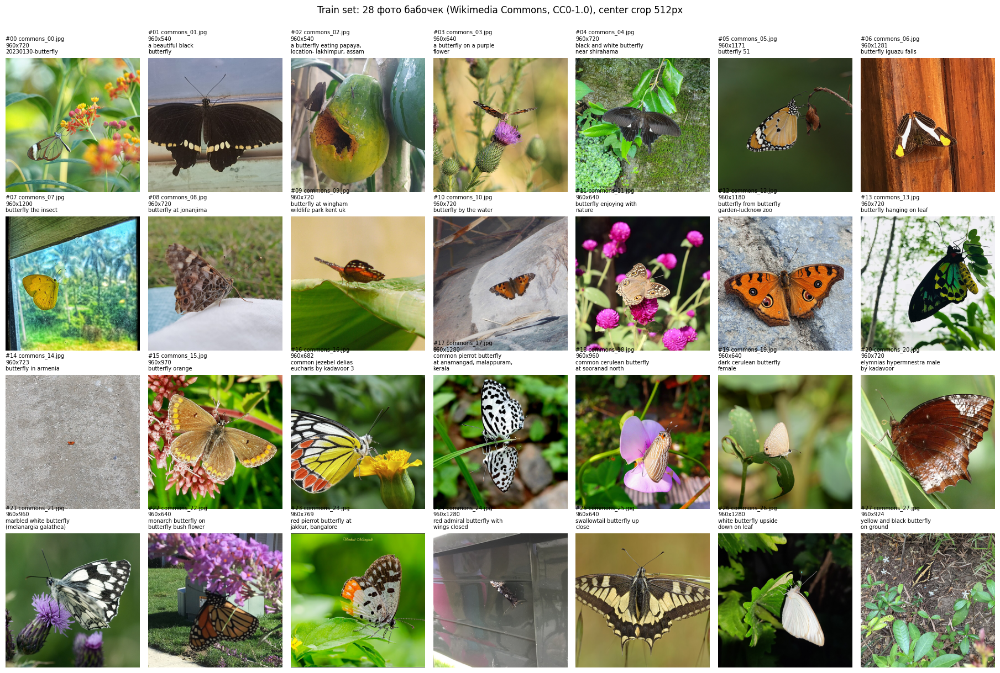

Сохранено: /content/drive/MyDrive/lab13/artifacts/task01_butterflies_grid.png


In [5]:
import textwrap
import matplotlib.pyplot as plt
from PIL import ImageOps

assert 'TRAIN_RECORDS' in globals(), 'Сначала выполните валидацию (TRAIN_RECORDS)'

PREVIEW = 256 if FAST_DEV_RUN else 512   # размер, который реально пойдёт в обучение
THUMB = 256                              # размер миниатюры в сетке
N = len(TRAIN_RECORDS)
COLS = 7
ROWS = (N + COLS - 1) // COLS

def short_caption(text, width=26, max_lines=3):
    text = text.removeprefix(CAPTION_PREFIX)
    lines = textwrap.wrap(text, width=width)
    if len(lines) > max_lines:
        lines = lines[:max_lines]
        lines[-1] = lines[-1][:width - 1] + '…'
    return '\n'.join(lines)

fig, axes = plt.subplots(ROWS, COLS, figsize=(COLS * 2.6, ROWS * 3.1))
axes = np.atleast_1d(axes).ravel()

for ax, (i, r) in zip(axes, enumerate(TRAIN_RECORDS)):
    with Image.open(LORA_DATA / r['file_name']) as im:
        im = im.convert('RGB')
        orig_size = im.size
        im = ImageOps.fit(im, (PREVIEW, PREVIEW), Image.LANCZOS)   # resize + center crop
        im = im.resize((THUMB, THUMB), Image.LANCZOS)
    ax.imshow(im)
    ax.set_title(f"#{i:02d} {r['file_name']}\n{orig_size[0]}x{orig_size[1]}\n{short_caption(r['text'])}",
                 fontsize=7, loc='left')
    ax.axis('off')

for ax in axes[N:]:   # пустые ячейки, если N не кратно COLS
    ax.axis('off')

fig.suptitle(f'Train set: {N} фото бабочек (Wikimedia Commons, CC0-1.0), center crop {PREVIEW}px',
             fontsize=12)
fig.tight_layout(rect=[0, 0, 1, 0.97])

out_png = ARTIFACTS / 'task01_butterflies_grid.png'
fig.savefig(out_png, dpi=130, bbox_inches='tight')
plt.show()
print('Сохранено:', out_png)

### Отложенные текстовые запросы

*Вес: 1 балл.*

**Постановка.** При малом наборе изображений утечка оценки в train captions делает сравнение LoRA некорректным. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями.

**Результат.** Проверяемое состояние «Отложенные текстовые запросы» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Зафиксируйте prompts и seeds, исключите точное совпадение с обучающими подписями» и его результат доступен следующему этапу.

In [6]:
import hashlib, re
from difflib import SequenceMatcher

assert 'TRAIN_RECORDS' in globals(), 'Сначала выполните валидацию данных (TRAIN_RECORDS)'

# --- 1. Зафиксированный набор (менять после просмотра результатов нельзя) ---
HELDOUT_PROMPTS = [
    # trigger: токен sks в новых контекстах. Проверяет, что адаптер обобщает, а не копирует train.
    {'id': 'p01', 'group': 'trigger', 'text': 'a photo of sks butterfly resting on a wooden fence'},
    {'id': 'p02', 'group': 'trigger', 'text': 'a photo of sks butterfly on a pink zinnia in a garden'},
    {'id': 'p03', 'group': 'trigger', 'text': 'a photo of sks butterfly with open wings on a stone wall'},
    {'id': 'p04', 'group': 'trigger', 'text': 'a photo of sks butterfly flying over a green meadow at sunrise'},
    {'id': 'p05', 'group': 'trigger', 'text': 'a macro photo of sks butterfly on a dandelion'},
    {'id': 'p06', 'group': 'trigger', 'text': 'a photo of sks butterfly sitting on a persons hand'},
    # plain: без sks. Честная точка сравнения с baseline, которая не знает токен sks.
    {'id': 'p07', 'group': 'plain', 'text': 'a photo of a butterfly on a sunflower'},
    # control: не бабочка. Показывает, не «протекает» ли адаптер на посторонние объекты.
    {'id': 'p08', 'group': 'control', 'text': 'a photo of a ladybug on a green leaf'},
]
GEN_SEEDS = [1001, 1002, 1003, 1004]
GEN_CONFIG = {'num_inference_steps': 30, 'guidance_scale': 7.5, 'negative_prompt': ''}
RESOLUTION = 256 if FAST_DEV_RUN else 512
TRAIN_SEEDS_RESERVED = {SEED, SEED + 1, SEED + 2}   # seeds обучения трёх адаптеров

# --- 2. Проверка утечки ---
def norm(s):
    return ' '.join(re.sub(r'[^a-z0-9 ]', ' ', s.lower()).split())

train_captions = [norm(r['text']) for r in TRAIN_RECORDS]
train_titles = [norm(r['text'].removeprefix(CAPTION_PREFIX)) for r in TRAIN_RECORDS]
SIM_LIMIT = 0.80

errors, leak_report = [], []
ids = [p['id'] for p in HELDOUT_PROMPTS]
texts = [norm(p['text']) for p in HELDOUT_PROMPTS]
if len(set(ids)) != len(ids): errors.append('id prompts не уникальны')
if len(set(texts)) != len(texts): errors.append('Есть повторяющиеся prompts')
if len(set(GEN_SEEDS)) != len(GEN_SEEDS): errors.append('Seeds не уникальны')
if TRAIN_SEEDS_RESERVED & set(GEN_SEEDS): errors.append('Seeds генерации пересекаются с seeds обучения')

for p, t in zip(HELDOUT_PROMPTS, texts):
    if p['group'] == 'trigger' and ' sks ' not in f' {t} ': errors.append(f"{p['id']}: нет токена sks")
    if p['group'] != 'trigger' and 'sks' in t.split():      errors.append(f"{p['id']}: sks вне группы trigger")
    best_sim, best_ref = 0.0, None
    for ref_norm, r in zip(train_captions, TRAIN_RECORDS):
        s = SequenceMatcher(None, t, ref_norm).ratio()
        if s > best_sim: best_sim, best_ref = s, r['text']
        if t == ref_norm:
            errors.append(f"{p['id']}: точно совпадает с train caption {r['file_name']}")
    for title_norm, r in zip(train_titles, TRAIN_RECORDS):
        s = SequenceMatcher(None, t, title_norm).ratio()
        if s > best_sim: best_sim, best_ref = s, r['text']
        if t == title_norm or title_norm in t:
            errors.append(f"{p['id']}: содержит train-название из {r['file_name']}: {title_norm!r}")
    if best_sim > SIM_LIMIT:
        errors.append(f"{p['id']}: слишком похож на train caption (sim={best_sim:.2f}): {best_ref!r}")
    leak_report.append({'id': p['id'], 'max_similarity': round(best_sim, 3), 'nearest_train_caption': best_ref})

# --- 3. Защита от подгонки: набор нельзя тихо изменить после первого запуска ---
spec = {'prompts': HELDOUT_PROMPTS, 'seeds': GEN_SEEDS, 'gen_config': GEN_CONFIG}
spec_sha = hashlib.sha256(json.dumps(spec, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
out_path = ARTIFACTS / 'task02_heldout_prompts.json'
if out_path.exists():
    old_sha = json.loads(out_path.read_text()).get('spec_sha256')
    if old_sha != spec_sha:
        errors.append('Набор prompts/seeds отличается от зафиксированного в artifacts. '
                      'Если это новый эксперимент, удалите файл осознанно.')

# --- 4. Активный набор для текущего режима ---
active_ids = ['p01', 'p07'] if FAST_DEV_RUN else ids
active_seeds = GEN_SEEDS[:1] if FAST_DEV_RUN else GEN_SEEDS
EVAL_CASES = [{'case_id': f"{p['id']}_s{seed}", 'prompt_id': p['id'], 'group': p['group'],
               'prompt': p['text'], 'seed': seed}
              for p in HELDOUT_PROMPTS if p['id'] in active_ids for seed in active_seeds]

report = {'status': 'passed' if not errors else 'failed', 'fast_dev_run': FAST_DEV_RUN,
          'spec_sha256': spec_sha, 'similarity_limit': SIM_LIMIT, 'resolution': RESOLUTION,
          'gen_config': GEN_CONFIG, 'seeds': GEN_SEEDS, 'train_seeds_reserved': sorted(TRAIN_SEEDS_RESERVED),
          'prompts': HELDOUT_PROMPTS, 'leak_check': leak_report,
          'active_case_count': len(EVAL_CASES), 'eval_cases': EVAL_CASES, 'errors': errors}
if not out_path.exists() or not errors or not any('зафиксированного' in e for e in errors):
    save_json('task02_heldout_prompts.json', report)

print(f"status={report['status']}, prompts={len(HELDOUT_PROMPTS)}, seeds={len(GEN_SEEDS)}, "
      f"cases в этом режиме={len(EVAL_CASES)}")
for row in leak_report:
    print(f"{row['id']}: max sim к train = {row['max_similarity']:.2f}")
assert not errors, 'Проверка не пройдена:\n' + '\n'.join(errors)

status=passed, prompts=8, seeds=4, cases в этом режиме=32
p01: max sim к train = 0.70
p02: max sim к train = 0.67
p03: max sim к train = 0.68
p04: max sim к train = 0.67
p05: max sim к train = 0.67
p06: max sim к train = 0.72
p07: max sim к train = 0.76
p08: max sim к train = 0.55


### Baseline SD на фиксированных запросах

*Вес: 1 балл.*

**Постановка.** Baseline до обучения и сопоставимый inference protocol позволяют увидеть фактический вклад LoRA. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds.

**Результат.** Проверяемое состояние «Baseline SD на фиксированных запросах» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите исходную SD1.5 на GPU и сгенерируйте baseline до установки адаптера на фиксированных запросах/seeds» и его результат доступен следующему этапу.

In [7]:
%pip install -q diffusers transformers accelerate peft safetensors torchvision pillow

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 13 files:   0%|          | 0/13 [00:00<?, ?it/s]

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

p01_s1001: 6.31 s
p01_s1002: 4.52 s
p01_s1003: 4.55 s
p01_s1004: 4.57 s
p02_s1001: 4.58 s
p02_s1002: 5.37 s
p02_s1003: 5.36 s
p02_s1004: 4.74 s
p03_s1001: 5.41 s
p03_s1002: 4.8 s
p03_s1003: 4.79 s
p03_s1004: 4.81 s
p04_s1001: 4.87 s
p04_s1002: 4.93 s
p04_s1003: 4.99 s
p04_s1004: 4.99 s
p05_s1001: 5.0 s
p05_s1002: 5.01 s
p05_s1003: 5.02 s
p05_s1004: 5.05 s
p06_s1001: 5.13 s
p06_s1002: 5.19 s
p06_s1003: 5.22 s
p06_s1004: 5.28 s
p07_s1001: 5.33 s
p07_s1002: 5.4 s
p07_s1003: 5.5 s
p07_s1004: 5.56 s
p08_s1001: 5.62 s
p08_s1002: 5.62 s
p08_s1003: 5.59 s
p08_s1004: 5.54 s


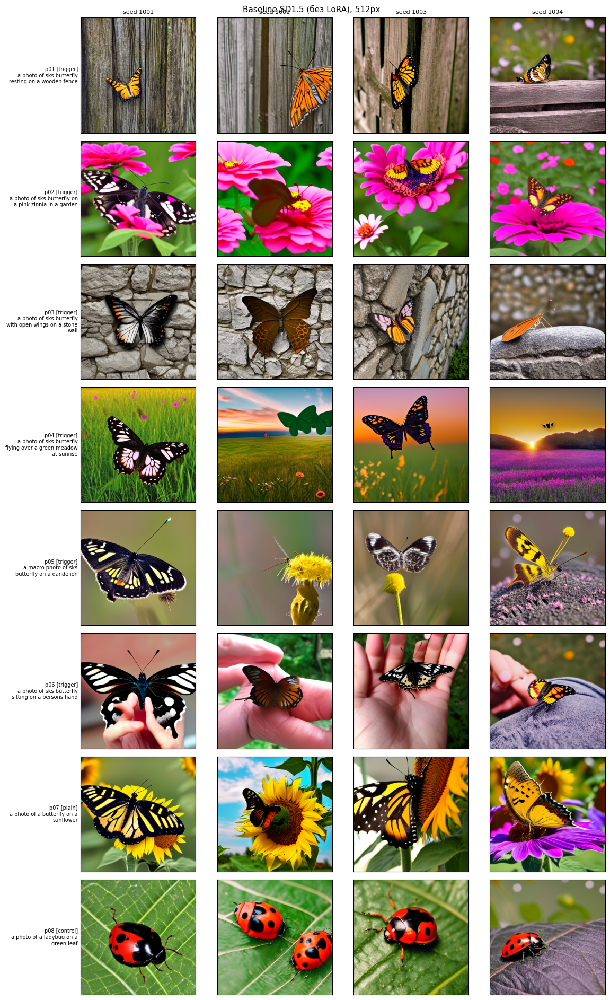

status=passed, images=32, repro mean|diff|=0.000, model=stable-diffusion-v1-5/stable-diffusion-v1-5@451f4fe1


In [8]:
import gc
from importlib.metadata import version, PackageNotFoundError
import matplotlib.pyplot as plt
from PIL import Image
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler
from huggingface_hub import HfApi

assert torch.cuda.is_available(), 'Нужен GPU: Runtime -> Change runtime type -> GPU. На CPU baseline не подменяем.'
assert 'EVAL_CASES' in globals() and EVAL_CASES, 'Сначала выполните задание 2 (EVAL_CASES)'

RUN_DIR = ARTIFACTS / ('fast_dev_run' if FAST_DEV_RUN else 'full_run')
BASELINE_DIR = RUN_DIR / 'generations' / 'baseline'
BASELINE_DIR.mkdir(parents=True, exist_ok=True)

# --- Версии для отчёта ---
def pkg_version(name):
    try: return version(name)
    except PackageNotFoundError: return None
VERSIONS = {n: pkg_version(n) for n in ['torch', 'torchvision', 'diffusers', 'transformers',
                                        'accelerate', 'peft', 'safetensors', 'pillow']}
GPU_NAME = torch.cuda.get_device_name(0)
save_json('environment.json', {'versions': VERSIONS, 'gpu': GPU_NAME, 'python': sys.version.split()[0]})

# --- Исходная SD1.5: фиксируем репозиторий и commit, чтобы адаптеры учились на тех же весах ---
MODEL_IDS = ['stable-diffusion-v1-5/stable-diffusion-v1-5', 'runwayml/stable-diffusion-v1-5']

def resolve_model():
    for mid in MODEL_IDS:
        try:
            return mid, HfApi().model_info(mid).sha
        except Exception as e:
            print(f'{mid}: недоступен ({type(e).__name__})')
    raise RuntimeError('Не найден репозиторий SD1.5 на Hugging Face Hub')

MODEL_ID, MODEL_REVISION = resolve_model()

def build_pipeline():
    """Чистая SD1.5 без адаптера. Одна и та же функция нужна и для baseline, и для LoRA-этапов."""
    pipe = StableDiffusionPipeline.from_pretrained(
        MODEL_ID, revision=MODEL_REVISION, torch_dtype=torch.float16,
        safety_checker=None, requires_safety_checker=False)
    pipe.scheduler = DPMSolverMultistepScheduler.from_config(pipe.scheduler.config)
    pipe.set_progress_bar_config(disable=True)
    return pipe.to('cuda')

def generate_case(pipe, case):
    g = torch.Generator(device='cuda').manual_seed(case['seed'])
    return pipe(prompt=case['prompt'],
                negative_prompt=GEN_CONFIG['negative_prompt'] or None,
                num_inference_steps=GEN_CONFIG['num_inference_steps'],
                guidance_scale=GEN_CONFIG['guidance_scale'],
                height=RESOLUTION, width=RESOLUTION, generator=g).images[0]

def generate_cases(pipe, cases, out_dir):
    """Единый протокол генерации для baseline и чекпоинтов LoRA."""
    out_dir.mkdir(parents=True, exist_ok=True)
    results = {}
    for c in cases:
        t0 = time.time()
        img = generate_case(pipe, c)
        path = out_dir / f"{c['case_id']}.png"
        img.save(path)
        results[c['case_id']] = {'path': path, 'seconds': round(time.time() - t0, 2)}
        print(f"{c['case_id']}: {results[c['case_id']]['seconds']} s")
    return results

# --- Генерация baseline ---
pipe = build_pipeline()
assert not hasattr(pipe.unet, 'peft_config'), 'В UNet уже есть адаптер: baseline должен быть до LoRA'
gen = generate_cases(pipe, EVAL_CASES, BASELINE_DIR)

# --- Проверка воспроизводимости seed: повторная генерация первого случая ---
first = EVAL_CASES[0]
a = np.asarray(Image.open(gen[first['case_id']]['path']).convert('RGB'), dtype=np.int16)
b = np.asarray(generate_case(pipe, first).convert('RGB'), dtype=np.int16)
repro = {'case_id': first['case_id'], 'mean_abs_diff': float(np.abs(a - b).mean()),
         'max_abs_diff': int(np.abs(a - b).max())}

del pipe; gc.collect(); torch.cuda.empty_cache()

# --- Валидация результата ---
errors, entries = [], []
for c in EVAL_CASES:
    p = gen[c['case_id']]['path']
    if not p.is_file() or p.stat().st_size == 0:
        errors.append(f"{c['case_id']}: нет файла"); continue
    with Image.open(p) as im:
        im = im.convert('RGB'); size = im.size
        arr = np.asarray(im, dtype=np.float32)
    if size != (RESOLUTION, RESOLUTION):
        errors.append(f"{c['case_id']}: размер {size}, ожидался {RESOLUTION}x{RESOLUTION}")
    if not np.isfinite(arr).all() or arr.std() < 1.0:
        errors.append(f"{c['case_id']}: пустая/чёрная картинка (возможен NaN в fp16)")
    entries.append({**c, 'path': str(p), 'seconds': gen[c['case_id']]['seconds'],
                    'sha256': hashlib.sha256(p.read_bytes()).hexdigest()})
if len({e['sha256'] for e in entries}) != len(entries):
    errors.append('Разные (prompt, seed) дали идентичные файлы')
if len(entries) != len(EVAL_CASES):
    errors.append(f'Сгенерировано {len(entries)} из {len(EVAL_CASES)}')
if repro['mean_abs_diff'] > 1.0:
    errors.append(f"Seed не воспроизводится: {repro}")

report = {'status': 'passed' if not errors else 'failed', 'fast_dev_run': FAST_DEV_RUN,
          'model_id': MODEL_ID, 'model_revision': MODEL_REVISION, 'dtype': 'float16',
          'scheduler': 'DPMSolverMultistepScheduler', 'safety_checker': None,
          'gen_config': GEN_CONFIG, 'resolution': RESOLUTION, 'gpu': GPU_NAME, 'versions': VERSIONS,
          'spec_sha256': json.loads((ARTIFACTS / 'task02_heldout_prompts.json').read_text())['spec_sha256'],
          'repro_check': repro, 'n_images': len(entries), 'cases': entries, 'errors': errors}
(RUN_DIR / 'task03_baseline.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))

BASELINE = {e['case_id']: e['path'] for e in entries}   # для следующих этапов

# --- Контактный лист: строки = prompts, столбцы = seeds ---
prompt_ids = list(dict.fromkeys(c['prompt_id'] for c in EVAL_CASES))
seeds = list(dict.fromkeys(c['seed'] for c in EVAL_CASES))
by_key = {(c['prompt_id'], c['seed']): c for c in EVAL_CASES}
fig, axes = plt.subplots(len(prompt_ids), len(seeds),
                         figsize=(2.4 * len(seeds) + 2.5, 2.4 * len(prompt_ids)), squeeze=False)
for i, pid in enumerate(prompt_ids):
    for j, sd in enumerate(seeds):
        ax = axes[i, j]
        c = by_key[(pid, sd)]
        if c['case_id'] in BASELINE:
            ax.imshow(Image.open(BASELINE[c['case_id']]))
        ax.set_xticks([]); ax.set_yticks([])
        if i == 0: ax.set_title(f'seed {sd}', fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{pid} [{c['group']}]\n" + textwrap.fill(c['prompt'], 28),
                          rotation=0, ha='right', va='center', fontsize=7)
fig.suptitle(f'Baseline SD1.5 (без LoRA), {RESOLUTION}px', fontsize=11)
fig.tight_layout()
fig.savefig(RUN_DIR / 'task03_baseline_grid.png', dpi=120, bbox_inches='tight')
plt.show()

print(f"status={report['status']}, images={len(entries)}, repro mean|diff|={repro['mean_abs_diff']:.3f}, "
      f"model={MODEL_ID}@{MODEL_REVISION[:8] if MODEL_REVISION else None}")
assert not errors, 'Baseline не принят:\n' + '\n'.join(errors)

### Подготовка пар изображение–caption

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон.

**Результат.** Проверяемое состояние «Подготовка пар изображение–caption» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Соберите Dataset с препроцессингом и токенизацией; проверьте длину и диапазон» и его результат доступен следующему этапу.

In [9]:
from PIL import Image, ImageOps
from transformers import CLIPTokenizer, CLIPTextConfig

for name in ['TRAIN_RECORDS', 'LORA_DATA', 'MODEL_ID', 'MODEL_REVISION', 'RUN_DIR', 'RESOLUTION', 'HELDOUT_PROMPTS']:
    assert name in globals(), f'Сначала выполните предыдущие задания: нет {name}'

EXPECTED_N = 28
TOKENIZER = CLIPTokenizer.from_pretrained(MODEL_ID, subfolder='tokenizer', revision=MODEL_REVISION)
TEXT_CFG = CLIPTextConfig.from_pretrained(MODEL_ID, subfolder='text_encoder', revision=MODEL_REVISION)
MAX_LEN = TOKENIZER.model_max_length   # 77 для SD1.5


class ButterflyCaptionDataset(torch.utils.data.Dataset):
    """Детерминированный препроцессинг: center crop -> resize -> [-1, 1]; caption -> input_ids."""
    def __init__(self, records, root, tokenizer, resolution):
        self.items = []
        for r in records:
            with Image.open(root / r['file_name']) as im:
                im = im.convert('RGB')
                src_size = im.size
                im = ImageOps.fit(im, (resolution, resolution), Image.LANCZOS)   # как в визуализации
            arr = np.asarray(im, dtype=np.float32)
            pixel_values = (torch.from_numpy(arr).permute(2, 0, 1) / 127.5 - 1.0).contiguous()
            input_ids = tokenizer(r['text'], max_length=tokenizer.model_max_length,
                                  padding='max_length', truncation=True,
                                  return_tensors='pt').input_ids[0]
            self.items.append({'file_name': r['file_name'], 'caption': r['text'], 'sha256': r['sha256'],
                               'src_size': src_size, 'pixel_values': pixel_values, 'input_ids': input_ids})

    def __len__(self):
        return len(self.items)

    def __getitem__(self, i):
        it = self.items[i]
        return {'pixel_values': it['pixel_values'], 'input_ids': it['input_ids']}


def collate_fn(batch):
    return {'pixel_values': torch.stack([b['pixel_values'] for b in batch]).float(),
            'input_ids': torch.stack([b['input_ids'] for b in batch])}


ds = ButterflyCaptionDataset(TRAIN_RECORDS, LORA_DATA, TOKENIZER, RESOLUTION)

# --- Проверки ---
errors, warnings, items_report = [], [], []
if len(ds) != EXPECTED_N: errors.append(f'Длина датасета {len(ds)}, ожидалось {EXPECTED_N}')
if [it['file_name'] for it in ds.items] != [r['file_name'] for r in TRAIN_RECORDS]:
    errors.append('Порядок датасета не совпадает с metadata.jsonl')
if MAX_LEN != TEXT_CFG.max_position_embeddings:
    errors.append(f'model_max_length={MAX_LEN} != max_position_embeddings={TEXT_CFG.max_position_embeddings}')

fp = hashlib.sha256(str(RESOLUTION).encode())
for it in ds.items:
    name, px, ids = it['file_name'], it['pixel_values'], it['input_ids']
    # изображение: форма, тип, диапазон
    if tuple(px.shape) != (3, RESOLUTION, RESOLUTION): errors.append(f'{name}: форма {tuple(px.shape)}')
    if px.dtype != torch.float32: errors.append(f'{name}: dtype {px.dtype}')
    if not torch.isfinite(px).all(): errors.append(f'{name}: NaN/inf в пикселях')
    lo, hi = float(px.min()), float(px.max())
    if lo < -1.0 - 1e-6 or hi > 1.0 + 1e-6: errors.append(f'{name}: диапазон [{lo:.3f}, {hi:.3f}] вне [-1, 1]')
    if float(px.std()) < 0.02: errors.append(f'{name}: почти константная картинка')
    # caption: длина, диапазон id, спецтокены, паддинг, отсутствие обрезки
    full = TOKENIZER(it['caption'], truncation=False).input_ids
    n_real = len(full)
    if n_real > MAX_LEN:
        errors.append(f'{name}: caption обрезается ({n_real} > {MAX_LEN} токенов)')
    else:
        if ids[:n_real].tolist() != full: errors.append(f'{name}: токены не совпадают с токенизацией без паддинга')
        if int(ids[n_real - 1]) != TOKENIZER.eos_token_id: errors.append(f'{name}: нет EOS в конце caption')
        if not bool((ids[n_real:] == TOKENIZER.pad_token_id).all()): errors.append(f'{name}: неверный паддинг')
    if tuple(ids.shape) != (MAX_LEN,) or ids.dtype != torch.long:
        errors.append(f'{name}: input_ids {tuple(ids.shape)} {ids.dtype}')
    if int(ids.min()) < 0 or int(ids.max()) >= TEXT_CFG.vocab_size:
        errors.append(f'{name}: id вне [0, {TEXT_CFG.vocab_size})')
    if int(ids[0]) != TOKENIZER.bos_token_id: errors.append(f'{name}: нет BOS в начале')
    # реальный масштаб: апсемплинг при кропе меньше целевого размера
    crop_side = min(it['src_size'])
    scale = RESOLUTION / crop_side
    items_report.append({'file_name': name, 'caption': it['caption'], 'n_tokens': n_real,
                         'src_size': list(it['src_size']), 'crop_side': crop_side,
                         'upscale_factor': round(scale, 3), 'pixel_min': round(lo, 4), 'pixel_max': round(hi, 4)})
    for chunk in (it['sha256'].encode(), it['caption'].encode(), ids.numpy().tobytes(), px.numpy().tobytes()):
        fp.update(chunk)
DATASET_FINGERPRINT = fp.hexdigest()

n_up = sum(r['upscale_factor'] > 1 for r in items_report)
if n_up:
    warnings.append(f'{n_up} из {len(items_report)} изображений апсемплируются при кропе '
                    f'(макс. x{max(r["upscale_factor"] for r in items_report):.2f}): превью Commons имеет ширину 640 px')

# prompts для оценки должны токенизироваться без обрезки тем же токенизатором
eval_token_lens = {}
for p in HELDOUT_PROMPTS:
    eval_token_lens[p['id']] = len(TOKENIZER(p['text'], truncation=False).input_ids)
    if eval_token_lens[p['id']] > MAX_LEN: errors.append(f"{p['id']}: prompt обрезается")

# DataLoader: формы батча
loader = torch.utils.data.DataLoader(ds, batch_size=4, shuffle=False, collate_fn=collate_fn)
batch = next(iter(loader))
if tuple(batch['pixel_values'].shape) != (4, 3, RESOLUTION, RESOLUTION) or tuple(batch['input_ids'].shape) != (4, MAX_LEN):
    errors.append(f"Форма батча: {tuple(batch['pixel_values'].shape)}, {tuple(batch['input_ids'].shape)}")

# Данные нельзя тихо изменить между экспериментами (rank/lr сравниваются на одних и тех же данных)
out_path = RUN_DIR / 'task04_dataset.json'
if out_path.exists():
    old = json.loads(out_path.read_text()).get('dataset_fingerprint')
    if old != DATASET_FINGERPRINT:
        errors.append('Отпечаток датасета отличается от сохранённого. Если данные менялись осознанно, удалите task04_dataset.json')

lens = [r['n_tokens'] for r in items_report]
report = {'status': 'passed' if not errors else 'failed', 'fast_dev_run': FAST_DEV_RUN,
          'n_items': len(ds), 'resolution': RESOLUTION, 'preprocessing': 'center crop + LANCZOS resize, [-1, 1], без аугментаций',
          'tokenizer': {'max_length': MAX_LEN, 'vocab_size': TEXT_CFG.vocab_size, 'bos_id': TOKENIZER.bos_token_id,
                        'eos_id': TOKENIZER.eos_token_id, 'pad_id': TOKENIZER.pad_token_id,
                        'sks_pieces': TOKENIZER.tokenize('sks')},
          'token_len': {'min': min(lens), 'max': max(lens), 'mean': round(float(np.mean(lens)), 2)},
          'eval_prompt_token_len': eval_token_lens, 'dataset_fingerprint': DATASET_FINGERPRINT,
          'warnings': warnings, 'errors': errors, 'items': items_report}
target = out_path if not errors else out_path.with_name('task04_dataset_failed.json')
target.write_text(json.dumps(report, ensure_ascii=False, indent=2))

print(f"status={report['status']}, n={len(ds)}, res={RESOLUTION}, tokens min/max/mean="
      f"{min(lens)}/{max(lens)}/{np.mean(lens):.1f} из {MAX_LEN}, fingerprint={DATASET_FINGERPRINT[:12]}")
print('sks ->', TOKENIZER.tokenize('sks'))
for w in warnings: print('WARNING:', w)
assert not errors, 'Dataset не принят:\n' + '\n'.join(errors)

TRAIN_DATASET = ds   # для следующих этапов: TRAIN_DATASET, collate_fn, TOKENIZER, DATASET_FINGERPRINT

status=passed, n=28, res=512, tokens min/max/mean=10/23/15.0 из 77, fingerprint=b21901e386ab
sks -> ['sks</w>']


### Заморозка основы и конфигурации LoRA

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR.

**Результат.** Проверяемое состояние «Заморозка основы и конфигурации LoRA» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Заморозьте основу, установите тренировочный schedule, выберите три конфигурации rank/LR» и его результат доступен следующему этапу.

In [10]:
%pip uninstall -y -q torchao

In [11]:
import gc
from diffusers import UNet2DConditionModel, AutoencoderKL, DDPMScheduler
from transformers import CLIPTextModel
from peft import LoraConfig
from peft.tuners.lora import LoraLayer

for name in ['MODEL_ID', 'MODEL_REVISION', 'RUN_DIR', 'RESOLUTION', 'TRAIN_DATASET', 'DATASET_FINGERPRINT', 'VERSIONS']:
    assert name in globals(), f'Сначала выполните предыдущие задания: нет {name}'
assert torch.cuda.is_available(), 'Нужен GPU'

# ---------- 1. Конфигурации и schedule (фиксируются до обучения) ----------
TARGET_MODULES = ['to_q', 'to_k', 'to_v', 'to_out.0']
LORA_COMMON = {'target_modules': TARGET_MODULES, 'lora_dropout': 0.0,
               'init_lora_weights': 'gaussian', 'alpha_equals_rank': True}

LORA_CONFIGS = [
    {'name': 'A_r4_lr1e-4',  'rank': 4,  'lora_alpha': 4,  'learning_rate': 1e-4},
    {'name': 'B_r16_lr1e-4', 'rank': 16, 'lora_alpha': 16, 'learning_rate': 1e-4},
    {'name': 'C_r16_lr5e-4', 'rank': 16, 'lora_alpha': 16, 'learning_rate': 5e-4},
]

TRAIN_SCHEDULE = {
    'total_updates': 1 if FAST_DEV_RUN else 400,
    'checkpoint_updates': [1] if FAST_DEV_RUN else [200, 400],
    'per_device_batch_size': 1,
    'grad_accum_steps': 1 if FAST_DEV_RUN else 4,
    'lr_schedule': 'constant_with_warmup',
    'warmup_updates': 0 if FAST_DEV_RUN else 20,
    'optimizer': 'AdamW', 'adam_betas': [0.9, 0.999], 'adam_eps': 1e-8, 'weight_decay': 1e-2,
    'max_grad_norm': 1.0,
    'precision': 'frozen weights fp16, LoRA params fp32, autocast fp16',
    'prediction_target': 'epsilon', 'timestep_sampling': 'uniform over [0, num_train_timesteps)',
    'gradient_checkpointing': True, 'seed': SEED, 'shuffle_data': True,
}
TRAIN_SCHEDULE['effective_batch_size'] = TRAIN_SCHEDULE['per_device_batch_size'] * TRAIN_SCHEDULE['grad_accum_steps']
TRAIN_SCHEDULE['samples_seen'] = TRAIN_SCHEDULE['total_updates'] * TRAIN_SCHEDULE['effective_batch_size']
TRAIN_SCHEDULE['epochs'] = round(TRAIN_SCHEDULE['samples_seen'] / len(TRAIN_DATASET), 2)


# ---------- 2. Функции, которые будет использовать этап обучения ----------
def freeze(module):
    module.requires_grad_(False)
    module.eval()
    return module

def load_frozen_components(device='cuda'):
    kw = dict(revision=MODEL_REVISION, torch_dtype=torch.float16)
    vae = freeze(AutoencoderKL.from_pretrained(MODEL_ID, subfolder='vae', **kw)).to(device)
    text_encoder = freeze(CLIPTextModel.from_pretrained(MODEL_ID, subfolder='text_encoder', **kw)).to(device)
    noise_scheduler = DDPMScheduler.from_pretrained(MODEL_ID, subfolder='scheduler', revision=MODEL_REVISION)
    return vae, text_encoder, noise_scheduler

def build_lora_unet(cfg, device='cuda'):
    """Чистый UNet SD1.5: основа заморожена, LoRA добавлена в attention, LoRA-веса в fp32.
    Модель возвращается в eval(); перед обучением вызовите unet.train()."""
    unet = UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder='unet', revision=MODEL_REVISION,
                                                torch_dtype=torch.float16)
    freeze(unet).to(device)
    unet.add_adapter(LoraConfig(r=cfg['rank'], lora_alpha=cfg['lora_alpha'],
                                init_lora_weights=LORA_COMMON['init_lora_weights'],
                                lora_dropout=LORA_COMMON['lora_dropout'], target_modules=TARGET_MODULES))
    for p in unet.parameters():
        if p.requires_grad:
            p.data = p.data.float()
    if TRAIN_SCHEDULE['gradient_checkpointing']:
        unet.enable_gradient_checkpointing()
    return unet

def make_optimizer_and_scheduler(params, cfg, schedule=None):
    schedule = schedule or TRAIN_SCHEDULE
    opt = torch.optim.AdamW(params, lr=cfg['learning_rate'], betas=tuple(schedule['adam_betas']),
                            eps=schedule['adam_eps'], weight_decay=schedule['weight_decay'])
    w = schedule['warmup_updates']
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda k: min(1.0, (k + 1) / w) if w > 0 else 1.0)
    return opt, sched

def is_target(name):
    return any(name == t or name.endswith('.' + t) for t in TARGET_MODULES)


# ---------- 3. Проверки ----------
errors, verification = [], {}
S = TRAIN_SCHEDULE

# 3.1 Логика выбора конфигураций
names = [c['name'] for c in LORA_CONFIGS]
A, B, C = LORA_CONFIGS
if len(LORA_CONFIGS) != 3 or len(set(names)) != 3: errors.append('Нужны ровно 3 конфигурации с уникальными именами')
if any(c['rank'] < 1 or c['learning_rate'] <= 0 or c['lora_alpha'] != c['rank'] for c in LORA_CONFIGS):
    errors.append('Некорректные rank/LR/alpha (alpha должен быть равен rank)')
if not (A['learning_rate'] == B['learning_rate'] and A['rank'] != B['rank']):
    errors.append('A->B должно менять только rank')
if not (B['rank'] == C['rank'] and B['learning_rate'] != C['learning_rate']):
    errors.append('B->C должно менять только LR')

# 3.2 Schedule
if not FAST_DEV_RUN and S['total_updates'] != 400: errors.append('В полном запуске нужно 400 updates')
if S['checkpoint_updates'] != ([1] if FAST_DEV_RUN else [200, 400]): errors.append('Чекпоинты должны быть на 200 и 400')
if S['checkpoint_updates'][-1] != S['total_updates']: errors.append('Последний чекпоинт должен быть на последнем update')
if S['effective_batch_size'] > len(TRAIN_DATASET): errors.append('Batch больше датасета')

dummy = torch.nn.Parameter(torch.zeros(1))
lr_trace = {}
for cfg in LORA_CONFIGS:
    opt, sch = make_optimizer_and_scheduler([dummy], cfg)
    lrs = []
    for _ in range(S['total_updates']):
        lrs.append(opt.param_groups[0]['lr'])
        dummy.grad = torch.zeros_like(dummy)
        opt.step(); sch.step()
    w = S['warmup_updates']
    expected = [cfg['learning_rate'] * (min(1.0, (k + 1) / w) if w > 0 else 1.0) for k in range(S['total_updates'])]
    if not np.allclose(lrs, expected, rtol=1e-6): errors.append(f"{cfg['name']}: LR schedule не совпал с ожидаемым")
    lr_trace[cfg['name']] = {'n_updates': len(lrs), 'first': lrs[0], 'warmup_end': lrs[max(w - 1, 0)], 'last': lrs[-1]}

# 3.3 VAE, text encoder, шумовой schedule
vae, text_encoder, noise_scheduler = load_frozen_components()
frozen_report = {}
for nm, m in [('vae', vae), ('text_encoder', text_encoder)]:
    n_train = sum(p.requires_grad for p in m.parameters())
    frozen_report[nm] = {'trainable_tensors': n_train, 'training_mode': m.training,
                         'n_params': sum(p.numel() for p in m.parameters())}
    if n_train or m.training: errors.append(f'{nm} не заморожен')
frozen_report['noise_scheduler'] = {'prediction_type': noise_scheduler.config.prediction_type,
                                    'num_train_timesteps': noise_scheduler.config.num_train_timesteps}
frozen_report['vae_scaling_factor'] = float(vae.config.scaling_factor)
if noise_scheduler.config.prediction_type != 'epsilon': errors.append('Ожидается prediction_type=epsilon')
del vae, text_encoder; gc.collect(); torch.cuda.empty_cache()

# 3.4 Базовый UNet: эталонный выход и список целевых слоёв
unet0 = freeze(UNet2DConditionModel.from_pretrained(MODEL_ID, subfolder='unet', revision=MODEL_REVISION,
                                                    torch_dtype=torch.float16)).to('cuda')
target_shapes = [(n, m.in_features, m.out_features) for n, m in unet0.named_modules()
                 if isinstance(m, torch.nn.Linear) and is_target(n)]
n_unet_params = sum(p.numel() for p in unet0.parameters())
g = torch.Generator('cpu').manual_seed(0)
probe_lat = torch.randn(1, 4, RESOLUTION // 8, RESOLUTION // 8, generator=g).half().cuda()
probe_ctx = torch.randn(1, 77, unet0.config.cross_attention_dim, generator=g).half().cuda()
probe_t = torch.tensor([500], device='cuda')
with torch.no_grad():
    base_out = unet0(probe_lat, probe_t, probe_ctx).sample.float().cpu()
del unet0; gc.collect(); torch.cuda.empty_cache()
if not target_shapes: errors.append('Не найдено целевых attention-слоёв')

# 3.5 Каждая конфигурация: заморозка, число параметров, нулевая инициализация
for cfg in LORA_CONFIGS:
    unet = build_lora_unet(cfg).eval()
    lora_layers = sum(isinstance(m, LoraLayer) for m in unet.modules())
    trainable = [(n, p) for n, p in unet.named_parameters() if p.requires_grad]
    n_trainable = sum(p.numel() for _, p in trainable)
    n_expected = sum(cfg['rank'] * (i + o) for _, i, o in target_shapes)
    not_lora = [n for n, _ in trainable if 'lora_' not in n]
    bad_dtype = [n for n, p in trainable if p.dtype != torch.float32]
    base_not_fp16 = [n for n, p in unet.named_parameters() if not p.requires_grad and p.dtype != torch.float16]
    with torch.no_grad():
        out = unet(probe_lat, probe_t, probe_ctx).sample.float().cpu()
    diff = float((out - base_out).abs().max())
    verification[cfg['name']] = {'lora_layers': lora_layers, 'target_linear_layers': len(target_shapes),
                                 'trainable_params': n_trainable, 'expected_trainable_params': n_expected,
                                 'trainable_fraction': n_trainable / (n_trainable + n_unet_params),
                                 'init_max_abs_diff_vs_base': diff}
    if lora_layers != len(target_shapes): errors.append(f"{cfg['name']}: LoRA в {lora_layers} слоях из {len(target_shapes)}")
    if n_trainable != n_expected: errors.append(f"{cfg['name']}: обучаемых {n_trainable}, ожидалось {n_expected}")
    if not_lora: errors.append(f"{cfg['name']}: обучаемые не-LoRA параметры: {not_lora[:3]}")
    if bad_dtype: errors.append(f"{cfg['name']}: LoRA не в fp32: {bad_dtype[:3]}")
    if base_not_fp16: errors.append(f"{cfg['name']}: основа не fp16: {base_not_fp16[:3]}")
    if diff > 1e-3: errors.append(f"{cfg['name']}: адаптер на старте меняет выход UNet (diff={diff:.2e})")
    del unet; gc.collect(); torch.cuda.empty_cache()

# 3.6 Фиксация: конфигурации нельзя подгонять после просмотра результатов
spec = {'configs': LORA_CONFIGS, 'common': LORA_COMMON, 'schedule': TRAIN_SCHEDULE,
        'dataset_fingerprint': DATASET_FINGERPRINT}
CONFIG_FINGERPRINT = hashlib.sha256(json.dumps(spec, sort_keys=True).encode()).hexdigest()
out_path = RUN_DIR / 'task05_lora_config.json'
if out_path.exists() and json.loads(out_path.read_text()).get('config_fingerprint') != CONFIG_FINGERPRINT:
    errors.append('Конфигурации/schedule/данные отличаются от сохранённых. Если это новый эксперимент, удалите task05_lora_config.json')

report = {'status': 'passed' if not errors else 'failed', 'fast_dev_run': FAST_DEV_RUN,
          'config_fingerprint': CONFIG_FINGERPRINT, 'dataset_fingerprint': DATASET_FINGERPRINT,
          'configs': LORA_CONFIGS, 'lora_common': LORA_COMMON, 'schedule': TRAIN_SCHEDULE,
          'design': 'A->B меняет только rank, B->C меняет только LR; seed обучения общий',
          'frozen_components': frozen_report, 'unet_base_params': n_unet_params,
          'verification': verification, 'lr_trace': lr_trace,
          'versions': VERSIONS, 'errors': errors}
target = out_path if not errors else out_path.with_name('task05_lora_config_failed.json')
target.write_text(json.dumps(report, ensure_ascii=False, indent=2))

print(f"status={report['status']}, updates={S['total_updates']}, eff.batch={S['effective_batch_size']}, "
      f"epochs={S['epochs']}, fingerprint={CONFIG_FINGERPRINT[:12]}")
for cfg in LORA_CONFIGS:
    v = verification[cfg['name']]
    print(f"{cfg['name']}: r={cfg['rank']}, lr={cfg['learning_rate']:.0e}, LoRA-слоёв={v['lora_layers']}, "
          f"обучаемых={v['trainable_params']:,} ({100 * v['trainable_fraction']:.2f}%), "
          f"diff на старте={v['init_max_abs_diff_vs_base']:.1e}")
assert not errors, 'Конфигурации не приняты:\n' + '\n'.join(errors)
# Для следующих этапов: LORA_CONFIGS, TRAIN_SCHEDULE, build_lora_unet, load_frozen_components,
# make_optimizer_and_scheduler, CONFIG_FINGERPRINT

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

status=passed, updates=400, eff.batch=4, epochs=57.14, fingerprint=f9e7a12b1125
A_r4_lr1e-4: r=4, lr=1e-04, LoRA-слоёв=128, обучаемых=797,184 (0.09%), diff на старте=0.0e+00
B_r16_lr1e-4: r=16, lr=1e-04, LoRA-слоёв=128, обучаемых=3,188,736 (0.37%), diff на старте=0.0e+00
C_r16_lr5e-4: r=16, lr=5e-04, LoRA-слоёв=128, обучаемых=3,188,736 (0.37%), diff на старте=0.0e+00


### Оптимизация адаптеров и checkpoint

*Вес: 1 балл.*

**Постановка.** Различия rank и learning rate оцениваются при одинаковых изображениях, количестве optimizer updates и eval prompts. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге.

**Результат.** Проверяемое состояние «Оптимизация адаптеров и checkpoint» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Обучите независимые адаптеры, сохраняйте optimizer, scaler и переносимые веса при каждом контрольном шаге» и его результат доступен следующему этапу.

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

A_r4_lr1e-4 update 25/400  loss(last25)=0.1727  lr=1.0e-04  eta≈10 мин
A_r4_lr1e-4 update 50/400  loss(last25)=0.1247  lr=1.0e-04  eta≈10 мин
A_r4_lr1e-4 update 75/400  loss(last25)=0.1670  lr=1.0e-04  eta≈9 мин
A_r4_lr1e-4 update 100/400  loss(last25)=0.1556  lr=1.0e-04  eta≈8 мин
A_r4_lr1e-4 update 125/400  loss(last25)=0.1534  lr=1.0e-04  eta≈7 мин
A_r4_lr1e-4 update 150/400  loss(last25)=0.1753  lr=1.0e-04  eta≈7 мин
A_r4_lr1e-4 update 175/400  loss(last25)=0.1556  lr=1.0e-04  eta≈6 мин
A_r4_lr1e-4 update 200/400  loss(last25)=0.1455  lr=1.0e-04  eta≈5 мин
A_r4_lr1e-4 update 225/400  loss(last25)=0.1621  lr=1.0e-04  eta≈5 мин
A_r4_lr1e-4 update 250/400  loss(last25)=0.1395  lr=1.0e-04  eta≈4 мин
A_r4_lr1e-4 update 275/400  loss(last25)=0.1500  lr=1.0e-04  eta≈3 мин
A_r4_lr1e-4 update 300/400  loss(last25)=0.1580  lr=1.0e-04  eta≈3 мин
A_r4_lr1e-4 update 325/400  loss(last25)=0.1612  lr=1.0e-04  eta≈2 мин
A_r4_lr1e-4 update 350/400  loss(last25)=0.1550  lr=1.0e-04  eta≈1 мин
A_r4_lr

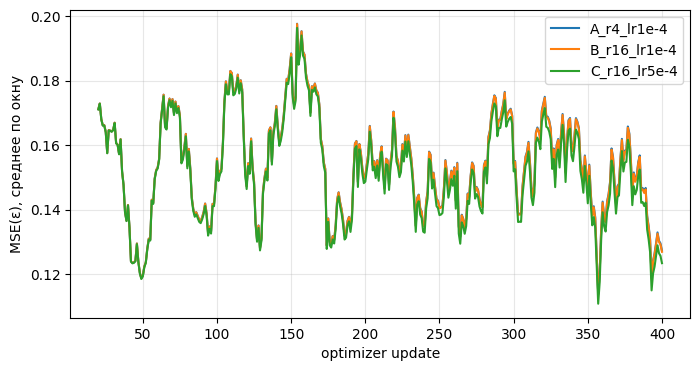

status=passed
A_r4_lr1e-4: loss 0.1487 -> 0.1405, пропущено шагов=0, пик GPU=2.17 ГБ, checkpoints=['200', '400']
B_r16_lr1e-4: loss 0.1487 -> 0.1401, пропущено шагов=0, пик GPU=2.2 ГБ, checkpoints=['200', '400']
C_r16_lr5e-4: loss 0.1486 -> 0.1367, пропущено шагов=0, пик GPU=2.2 ГБ, checkpoints=['200', '400']


In [12]:
import shutil, math, inspect
import torch.nn.functional as F
import matplotlib.pyplot as plt
from peft.utils import get_peft_model_state_dict, set_peft_model_state_dict
from diffusers import StableDiffusionPipeline
from diffusers.utils import convert_state_dict_to_diffusers
from safetensors.torch import load_file

for name in ['LORA_CONFIGS', 'TRAIN_SCHEDULE', 'build_lora_unet', 'load_frozen_components',
             'make_optimizer_and_scheduler', 'CONFIG_FINGERPRINT', 'DATASET_FINGERPRINT',
             'TRAIN_DATASET', 'collate_fn', 'RUN_DIR', 'target_shapes']:
    assert name in globals(), f'Сначала выполните предыдущие задания: нет {name}'
assert torch.cuda.is_available(), 'Нужен GPU'
S = TRAIN_SCHEDULE
assert S['per_device_batch_size'] == 1

RUN_CONFIGS = [c['name'] for c in LORA_CONFIGS]   # можно сузить до одного имени, чтобы обучать по одному за сессию
ADAPTER_ROOT = RUN_DIR / 'adapters'
ADAPTER_ROOT.mkdir(parents=True, exist_ok=True)
N = len(TRAIN_DATASET)

# ---------- 1. Предвычисления (VAE и text encoder заморожены) ----------
vae, text_encoder, noise_scheduler = load_frozen_components()
assert noise_scheduler.config.prediction_type == 'epsilon'
VAE_SCALE = float(vae.config.scaling_factor)
means, stds, embs = [], [], []
with torch.no_grad():
    for i in range(0, N, 4):
        batch = collate_fn([TRAIN_DATASET[j] for j in range(i, min(i + 4, N))])
        dist = vae.encode(batch['pixel_values'].to('cuda', torch.float16)).latent_dist
        means.append(dist.mean.float()); stds.append(dist.std.float())
        embs.append(text_encoder(batch['input_ids'].to('cuda'))[0])
LAT_MEAN, LAT_STD, TEXT_EMB = torch.cat(means), torch.cat(stds), torch.cat(embs)
del vae, text_encoder; gc.collect(); torch.cuda.empty_cache()
assert tuple(LAT_MEAN.shape) == (N, 4, RESOLUTION // 8, RESOLUTION // 8), LAT_MEAN.shape
assert tuple(TEXT_EMB.shape) == (N, 77, 768), TEXT_EMB.shape
assert torch.isfinite(LAT_MEAN).all() and torch.isfinite(LAT_STD).all() and torch.isfinite(TEXT_EMB).all()
LATENT_STD_SCALED = float((LAT_MEAN * VAE_SCALE).std())

# ---------- 2. Детерминированные порядок данных и шум ----------
_perm_cache = {}
def sample_index(m):
    epoch, pos = divmod(m, N)
    if epoch not in _perm_cache:
        g = torch.Generator().manual_seed(S['seed'] * 10007 + epoch)
        _perm_cache[epoch] = torch.randperm(N, generator=g)
    return int(_perm_cache[epoch][pos])

def micro_loss(unet, idx, m):
    gen = torch.Generator(device='cuda'); gen.manual_seed(S['seed'] * 1_000_003 + m)
    shape = (1, 4, RESOLUTION // 8, RESOLUTION // 8)
    z = torch.randn(shape, device='cuda', generator=gen)
    latents = (LAT_MEAN[idx:idx + 1] + LAT_STD[idx:idx + 1] * z) * VAE_SCALE
    noise = torch.randn(shape, device='cuda', generator=gen)
    t = torch.randint(0, noise_scheduler.config.num_train_timesteps, (1,), device='cuda', generator=gen).long()
    noisy = noise_scheduler.add_noise(latents, noise, t)
    with torch.autocast('cuda', dtype=torch.float16):
        pred = unet(noisy.half(), t, TEXT_EMB[idx:idx + 1]).sample
    return F.mse_loss(pred.float(), noise)          # epsilon-prediction


# ---------- 3. Checkpoints ----------
def ckpt_update(path): return int(path.name.split('-')[-1])

def find_latest_checkpoint(out_dir):
    done = sorted((p for p in out_dir.glob('checkpoint-*') if (p / 'COMPLETE').exists()), key=ckpt_update)
    return done[-1] if done else None

def save_checkpoint(cfg, unet, opt, sched, scaler, update, history, out_dir):
    final = out_dir / f'checkpoint-{update:04d}'
    tmp = out_dir / f'.tmp-checkpoint-{update:04d}'
    for d in (tmp, final):
        if d.exists(): shutil.rmtree(d)
    tmp.mkdir(parents=True)
    params = [p for p in unet.parameters() if p.requires_grad]
    peft_sd = {k: v.detach().cpu().clone() for k, v in get_peft_model_state_dict(unet).items()}
    diffusers_sd = convert_state_dict_to_diffusers(peft_sd)
    StableDiffusionPipeline.save_lora_weights(save_directory=str(tmp), unet_lora_layers=diffusers_sd,
                                              safe_serialization=True)
    torch.save({'update': update, 'micro_step': update * S['grad_accum_steps'], 'lora_peft_state': peft_sd,
                'optimizer': opt.state_dict(), 'scheduler': sched.state_dict(), 'scaler': scaler.state_dict(),
                'history': history, 'cfg': cfg, 'schedule': S,
                'config_fingerprint': CONFIG_FINGERPRINT, 'dataset_fingerprint': DATASET_FINGERPRINT},
               tmp / 'training_state.pt')

    # проверка: переносимые веса и состояние обучения читаются обратно и совпадают с моделью
    problems = []
    w_path = tmp / 'pytorch_lora_weights.safetensors'
    w = {k.removeprefix('unet.'): v for k, v in load_file(str(w_path)).items()}
    if set(w) != set(diffusers_sd): problems.append('ключи файла весов отличаются от модели')
    else:
        if not all(torch.equal(w[k].float(), diffusers_sd[k].float()) for k in w): problems.append('веса в файле != веса модели')
    if len(w) != 2 * len(target_shapes): problems.append(f'тензоров {len(w)}, ожидалось {2 * len(target_shapes)}')
    if not all(torch.isfinite(v).all() for v in w.values()): problems.append('NaN/inf в весах')
    st = torch.load(tmp / 'training_state.pt', map_location='cpu', weights_only=False)
    if st['scheduler']['last_epoch'] != update: problems.append('scheduler.last_epoch != update')
    opt2, _ = make_optimizer_and_scheduler(params, cfg)
    opt2.load_state_dict(st['optimizer'])
    for p in params:
        if p in opt.state and not torch.equal(opt.state[p]['exp_avg'], opt2.state[p]['exp_avg']):
            problems.append('состояние optimizer не восстанавливается'); break
    del opt2
    if problems:
        raise RuntimeError(f'Checkpoint {update} не прошёл проверку: {problems} (папка {tmp} оставлена для отладки)')

    meta = {'update': update, 'config': cfg, 'weights_file': w_path.name,
            'weights_sha256': hashlib.sha256(w_path.read_bytes()).hexdigest(), 'weights_bytes': w_path.stat().st_size,
            'n_tensors': len(w), 'rank': cfg['rank'], 'lora_alpha': cfg['lora_alpha'],
            'target_modules': TARGET_MODULES, 'config_fingerprint': CONFIG_FINGERPRINT,
            'dataset_fingerprint': DATASET_FINGERPRINT, 'loss_last50': float(np.mean([h['loss'] for h in history[-50:]])),
            'skipped_updates_so_far': int(sum(h['skipped'] for h in history))}
    (tmp / 'meta.json').write_text(json.dumps(meta, ensure_ascii=False, indent=2))
    (tmp / 'COMPLETE').write_text('ok')
    tmp.rename(final)
    return meta


# ---------- 4. Обучение одного адаптера (с возобновлением) ----------
def train_adapter(cfg):
    out_dir = ADAPTER_ROOT / cfg['name']
    out_dir.mkdir(parents=True, exist_ok=True)
    for tmp in out_dir.glob('.tmp-*'): shutil.rmtree(tmp)
    latest = find_latest_checkpoint(out_dir)
    result_path = out_dir / 'result.json'
    if latest is not None and ckpt_update(latest) == S['total_updates'] and result_path.exists():
        res = json.loads(result_path.read_text())
        if res.get('config_fingerprint') == CONFIG_FINGERPRINT:
            res['reused_from_disk'] = True
            print(f"{cfg['name']}: уже обучен, результат взят с диска")
            return res
        raise RuntimeError(f"{cfg['name']}: на диске результат другой конфигурации. Удалите папку {out_dir}")

    torch.manual_seed(S['seed'])
    unet = build_lora_unet(cfg)
    unet.train()
    params = [p for p in unet.parameters() if p.requires_grad]
    opt, sched = make_optimizer_and_scheduler(params, cfg)
    scaler = torch.amp.GradScaler('cuda', init_scale=1024.0)
    start, history = 0, []
    if latest is not None:
        st = torch.load(latest / 'training_state.pt', map_location='cpu', weights_only=False)
        if st['config_fingerprint'] != CONFIG_FINGERPRINT or st['dataset_fingerprint'] != DATASET_FINGERPRINT:
            raise RuntimeError(f'{latest}: checkpoint от другой конфигурации или данных')
        load_res = set_peft_model_state_dict(unet, st['lora_peft_state'])
        assert not getattr(load_res, 'unexpected_keys', None), load_res.unexpected_keys
        opt.load_state_dict(st['optimizer']); sched.load_state_dict(st['scheduler']); scaler.load_state_dict(st['scaler'])
        start, history = st['update'], st['history']
        print(f"{cfg['name']}: возобновляю с update {start}")

    base_named = [(n, p) for n, p in unet.named_parameters() if 'lora_' not in n]
    base_snap = {n: p.detach().cpu().clone() for n, p in base_named[::8]}   # контроль неизменности основы
    torch.cuda.reset_peak_memory_stats()
    t0, grad_checked = time.time(), False

    for u in range(start, S['total_updates']):
        scale_before = scaler.get_scale()
        loss_sum = torch.zeros((), device='cuda')
        for j in range(S['grad_accum_steps']):
            m = u * S['grad_accum_steps'] + j
            loss = micro_loss(unet, sample_index(m), m)
            scaler.scale(loss / S['grad_accum_steps']).backward()
            loss_sum += loss.detach()
            if not grad_checked:
                if not any(p.grad is not None for p in params):
                    raise RuntimeError('Градиенты не доходят до LoRA-параметров (проверьте gradient checkpointing)')
                grad_checked = True
        scaler.unscale_(opt)
        gn = float(torch.nn.utils.clip_grad_norm_(params, S['max_grad_norm']))
        lr_used = opt.param_groups[0]['lr']
        scaler.step(opt); scaler.update()
        skipped = scaler.get_scale() < scale_before        # шаг пропущен из-за inf/nan в градиентах
        sched.step(); opt.zero_grad(set_to_none=True)
        history.append({'update': u + 1, 'loss': float(loss_sum) / S['grad_accum_steps'], 'lr': lr_used,
                        'grad_norm': gn if math.isfinite(gn) else None, 'scale': scaler.get_scale(),
                        'skipped': bool(skipped)})
        if (u + 1) % 25 == 0 or (u + 1) == S['total_updates']:
            done = u + 1 - start
            eta = (time.time() - t0) / done * (S['total_updates'] - u - 1) / 60
            print(f"{cfg['name']} update {u + 1}/{S['total_updates']}  loss(last25)="
                  f"{np.mean([h['loss'] for h in history[-25:]]):.4f}  lr={lr_used:.1e}  eta≈{eta:.0f} мин")
        if (u + 1) in S['checkpoint_updates']:
            save_checkpoint(cfg, unet, opt, sched, scaler, u + 1, history, out_dir)

    # --- итоговые проверки адаптера ---
    errors = []
    base_unchanged = all(torch.equal(base_snap[n], p.detach().cpu()) for n, p in base_named[::8])
    non_lora_trainable = [n for n, p in unet.named_parameters() if p.requires_grad and 'lora_' not in n]
    b_norm = math.sqrt(sum(float(p.detach().double().pow(2).sum()) for n, p in unet.named_parameters() if 'lora_B' in n))
    skipped_total = int(sum(h['skipped'] for h in history))
    losses = [h['loss'] for h in history]
    if len(history) != S['total_updates']: errors.append(f'в логе {len(history)} updates из {S["total_updates"]}')
    if not all(math.isfinite(x) for x in losses): errors.append('NaN/inf в loss')
    if not base_unchanged: errors.append('веса основы изменились')
    if non_lora_trainable: errors.append(f'обучались не-LoRA параметры: {non_lora_trainable[:3]}')
    if b_norm <= 0: errors.append('матрицы B остались нулевыми: адаптер не обучился')
    if skipped_total > max(2, int(0.02 * S['total_updates'])):
        errors.append(f'слишком много пропущенных шагов GradScaler: {skipped_total}')
    ckpts = {}
    for cu in S['checkpoint_updates']:
        d = out_dir / f'checkpoint-{cu:04d}'
        if not (d / 'COMPLETE').exists(): errors.append(f'нет checkpoint {cu}'); continue
        ckpts[str(cu)] = json.loads((d / 'meta.json').read_text()) | {'dir': str(d)}
    if len(ckpts) >= 2:
        first, last = (out_dir / f'checkpoint-{cu:04d}' / 'pytorch_lora_weights.safetensors'
                       for cu in (S['checkpoint_updates'][0], S['checkpoint_updates'][-1]))
        w1, w2 = load_file(str(first)), load_file(str(last))
        if all(torch.equal(w1[k], w2[k]) for k in w1): errors.append('веса на первом и последнем checkpoint совпадают')

    result = {'name': cfg['name'], 'config': cfg, 'config_fingerprint': CONFIG_FINGERPRINT,
              'dataset_fingerprint': DATASET_FINGERPRINT, 'status': 'passed' if not errors else 'failed',
              'updates': len(history), 'skipped_updates': skipped_total,
              'loss_first50': float(np.mean(losses[:50])), 'loss_last50': float(np.mean(losses[-50:])),
              'lora_B_norm': b_norm, 'peak_gpu_gb': round(torch.cuda.max_memory_allocated() / 2**30, 2),
              'train_minutes_this_session': round((time.time() - t0) / 60, 1),
              'checkpoints': ckpts, 'errors': errors, 'history': history}
    result_path.write_text(json.dumps(result, ensure_ascii=False, indent=2))
    del unet, opt, sched, scaler; gc.collect(); torch.cuda.empty_cache()
    return result


# ---------- 5. Запуск ----------
results = {}
for cfg in LORA_CONFIGS:
    if cfg['name'] in RUN_CONFIGS:
        results[cfg['name']] = train_adapter(cfg)

all_errors = [f"{n}: {e}" for n, r in results.items() for e in r['errors']]
complete = all(c['name'] in results for c in LORA_CONFIGS)
report = {'status': 'failed' if all_errors else ('passed' if complete else 'partial'),
          'fast_dev_run': FAST_DEV_RUN, 'config_fingerprint': CONFIG_FINGERPRINT,
          'dataset_fingerprint': DATASET_FINGERPRINT, 'schedule': S, 'versions': VERSIONS,
          'latent_std_after_scaling': LATENT_STD_SCALED,
          'adapters': {n: {k: v for k, v in r.items() if k != 'history'} for n, r in results.items()},
          'errors': all_errors}
(RUN_DIR / 'task06_training.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))

# кривые loss
if S['total_updates'] >= 20:
    fig, ax = plt.subplots(figsize=(8, 4))
    for n, r in results.items():
        l = np.array([h['loss'] for h in r['history']])
        win = min(20, len(l))
        ax.plot(np.arange(win, len(l) + 1), np.convolve(l, np.ones(win) / win, mode='valid'), label=n)
    ax.set_xlabel('optimizer update'); ax.set_ylabel(f'MSE(ε), среднее по окну'); ax.legend(); ax.grid(alpha=.3)
    fig.savefig(RUN_DIR / 'task06_loss_curves.png', dpi=130, bbox_inches='tight'); plt.show()

print(f"status={report['status']}")
for n, r in results.items():
    print(f"{n}: loss {r['loss_first50']:.4f} -> {r['loss_last50']:.4f}, пропущено шагов={r['skipped_updates']}, "
          f"пик GPU={r['peak_gpu_gb']} ГБ, checkpoints={list(r['checkpoints'])}")
if report['status'] == 'partial':
    print('Обучены не все конфигурации: расширьте RUN_CONFIGS и запустите ячейку снова (готовые адаптеры пропускаются).')
assert not all_errors, 'Обучение не принято:\n' + '\n'.join(all_errors)

ADAPTERS = results   # для следующих этапов: ADAPTERS[name]['checkpoints'][str(update)]['dir']

Проверка

### Признаки CLIP для независимой оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings.

**Результат.** Проверяемое состояние «Признаки CLIP для независимой оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Загрузите CLIP и определите нормализованные текстовые и визуальные embeddings» и его результат доступен следующему этапу.

In [13]:
# ============================================================
# ГЕНЕРАЦИЯ BASELINE И ТРЁХ LoRA-АДАПТЕРОВ
# ============================================================
import gc
import json
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from diffusers import StableDiffusionPipeline, DPMSolverMultistepScheduler

assert 'EVAL_CASES' in globals() and EVAL_CASES
assert 'LORA_CONFIGS' in globals()
assert 'RUN_DIR' in globals()
assert torch.cuda.is_available(), 'Для генерации необходим GPU'

GENERATION_ROOT = RUN_DIR / 'generations'
GENERATION_ROOT.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 1. Baseline: используем ранее сгенерированные изображения.
# ------------------------------------------------------------

assert 'BASELINE' in globals(), 'Сначала выполните генерацию baseline'

GENERATION_RESULTS = {
    'baseline': {
        'label': 'Baseline SD1.5',
        'images': {}
    }
}

for case in EVAL_CASES:
    case_id = case['case_id']
    path = Path(BASELINE[case_id])

    assert path.exists() and path.stat().st_size > 0, (
        f'Нет baseline изображения: {path}'
    )

    GENERATION_RESULTS['baseline']['images'][case_id] = str(path)

print(f"Baseline: {len(GENERATION_RESULTS['baseline']['images'])} изображений")

# ------------------------------------------------------------
# 2. Поиск последнего успешно сохранённого checkpoint.
# ------------------------------------------------------------

def get_best_checkpoint(adapter_name):
    adapter_dir = ADAPTER_ROOT / adapter_name

    checkpoints = [
        p for p in adapter_dir.glob('checkpoint-*')
        if (p / 'COMPLETE').exists()
        and (p / 'pytorch_lora_weights.safetensors').exists()
    ]

    checkpoints.sort(
        key=lambda p: int(p.name.split('-')[-1])
    )

    if not checkpoints:
        raise FileNotFoundError(
            f'У адаптера {adapter_name} нет готовых checkpoints'
        )

    return checkpoints[-1]


# ------------------------------------------------------------
# 3. Генерация каждого адаптера.
# ------------------------------------------------------------

ADAPTER_GENERATION_REPORT = {}

for cfg in LORA_CONFIGS:

    adapter_name = cfg['name']
    checkpoint = get_best_checkpoint(adapter_name)

    update = int(checkpoint.name.split('-')[-1])

    print('\n' + '=' * 65)
    print(f'Адаптер: {adapter_name}')
    print(f'Checkpoint: {checkpoint.name}')
    print(f'Optimizer updates: {update}')
    print('=' * 65)

    output_dir = GENERATION_ROOT / adapter_name
    output_dir.mkdir(parents=True, exist_ok=True)

    # Загружаем чистую SD1.5.
    adapter_pipe = build_pipeline()

    # Загружаем выбранные веса LoRA.
    adapter_pipe.load_lora_weights(str(checkpoint))

    # Генерируем на тех же prompts и seeds.
    adapter_images = generate_cases(
        adapter_pipe,
        EVAL_CASES,
        output_dir
    )

    GENERATION_RESULTS[adapter_name] = {
        'label': adapter_name,
        'checkpoint': str(checkpoint),
        'update': update,
        'images': {
            case_id: str(info['path'])
            for case_id, info in adapter_images.items()
        }
    }

    ADAPTER_GENERATION_REPORT[adapter_name] = {
        'checkpoint': str(checkpoint),
        'update': update,
        'n_images': len(adapter_images),
        'status': 'passed'
    }

    # Освобождаем память перед следующим адаптером.
    del adapter_pipe
    gc.collect()
    torch.cuda.empty_cache()

    print(
        f'Готово: {len(adapter_images)} изображений '
        f'для {adapter_name}'
    )

# ------------------------------------------------------------
# 4. Проверка полноты генерации.
# ------------------------------------------------------------

errors = []

for model_name, model_data in GENERATION_RESULTS.items():

    if len(model_data['images']) != len(EVAL_CASES):
        errors.append(
            f'{model_name}: получено {len(model_data["images"])} '
            f'изображений вместо {len(EVAL_CASES)}'
        )

    for case_id, path in model_data['images'].items():
        p = Path(path)

        if not p.exists() or p.stat().st_size == 0:
            errors.append(f'{model_name}/{case_id}: файл отсутствует')

assert not errors, '\n'.join(errors)

# ------------------------------------------------------------
# 5. Сохранение результата.
# ------------------------------------------------------------

generation_report = {
    'status': 'passed',
    'resolution': RESOLUTION,
    'n_prompts': len(HELDOUT_PROMPTS),
    'n_seeds': len(GEN_SEEDS),
    'n_cases': len(EVAL_CASES),
    'models': {
        name: {
            'label': data['label'],
            'checkpoint': data.get('checkpoint'),
            'update': data.get('update'),
            'images': data['images']
        }
        for name, data in GENERATION_RESULTS.items()
    }
}

generation_json = RUN_DIR / 'task07_generation.json'

generation_json.write_text(
    json.dumps(generation_report, ensure_ascii=False, indent=2)
)

print('\n' + '=' * 65)
print('ГЕНЕРАЦИЯ ЗАВЕРШЕНА')
print('=' * 65)

for name, data in GENERATION_RESULTS.items():
    print(f"{data['label']}: {len(data['images'])} изображений")

print('Отчёт:', generation_json)

# Для следующего этапа:
# GENERATION_RESULTS — пути ко всем изображениям.


Baseline: 32 изображений

Адаптер: A_r4_lr1e-4
Checkpoint: checkpoint-0400
Optimizer updates: 400


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


p01_s1001: 5.68 s
p01_s1002: 5.87 s
p01_s1003: 6.09 s
p01_s1004: 6.22 s
p02_s1001: 6.19 s
p02_s1002: 5.91 s
p02_s1003: 5.82 s
p02_s1004: 5.61 s
p03_s1001: 5.48 s
p03_s1002: 5.44 s
p03_s1003: 5.46 s
p03_s1004: 5.44 s
p04_s1001: 5.47 s
p04_s1002: 5.52 s
p04_s1003: 5.59 s
p04_s1004: 5.64 s
p05_s1001: 5.74 s
p05_s1002: 5.78 s
p05_s1003: 5.78 s
p05_s1004: 5.79 s
p06_s1001: 5.8 s
p06_s1002: 5.83 s
p06_s1003: 5.69 s
p06_s1004: 5.64 s
p07_s1001: 5.62 s
p07_s1002: 5.61 s
p07_s1003: 5.62 s
p07_s1004: 5.59 s
p08_s1001: 5.59 s
p08_s1002: 5.64 s
p08_s1003: 5.67 s
p08_s1004: 5.68 s
Готово: 32 изображений для A_r4_lr1e-4

Адаптер: B_r16_lr1e-4
Checkpoint: checkpoint-0400
Optimizer updates: 400


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

... (3 outputs left out)

Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


p01_s1001: 5.47 s
p01_s1002: 5.59 s
p01_s1003: 5.81 s
p01_s1004: 5.96 s
p02_s1001: 6.17 s
p02_s1002: 6.2 s
p02_s1003: 6.02 s
p02_s1004: 5.84 s
p03_s1001: 5.67 s
p03_s1002: 5.54 s
p03_s1003: 5.51 s
p03_s1004: 5.48 s
p04_s1001: 5.47 s
p04_s1002: 5.46 s
p04_s1003: 5.54 s
p04_s1004: 5.54 s
p05_s1001: 5.59 s
p05_s1002: 5.67 s
p05_s1003: 5.75 s
p05_s1004: 5.78 s
p06_s1001: 5.82 s
p06_s1002: 5.83 s
p06_s1003: 5.82 s
p06_s1004: 5.75 s
p07_s1001: 5.71 s
p07_s1002: 5.68 s
p07_s1003: 5.65 s
p07_s1004: 5.6 s
p08_s1001: 5.64 s
p08_s1002: 5.62 s
p08_s1003: 5.63 s
p08_s1004: 5.59 s
Готово: 32 изображений для C_r16_lr5e-4

ГЕНЕРАЦИЯ ЗАВЕРШЕНА
Baseline SD1.5: 32 изображений
A_r4_lr1e-4: 32 изображений
B_r16_lr1e-4: 32 изображений
C_r16_lr5e-4: 32 изображений
Отчёт: /content/drive/MyDrive/lab13/artifacts/full_run/task07_generation.json


preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/905 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/961k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

... (2 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

CLIP model: openai/clip-vit-large-patch14
Device: cuda

Обработка: Baseline SD1.5
Images: 32, similarity mean: 0.2852, std: 0.0209

Обработка: A_r4_lr1e-4
Images: 32, similarity mean: 0.2805, std: 0.0217

Обработка: B_r16_lr1e-4
Images: 32, similarity mean: 0.2802, std: 0.0241

Обработка: C_r16_lr5e-4
Images: 32, similarity mean: 0.2904, std: 0.0302

CLIP embeddings сохранены: /content/drive/MyDrive/lab13/artifacts/full_run/task08_clip_embeddings.npz
Метрики сохранены: /content/drive/MyDrive/lab13/artifacts/full_run/task08_clip_metrics.json
Подробные результаты: /content/drive/MyDrive/lab13/artifacts/full_run/task08_clip_details.json


/tmp/ipykernel_677/1441293386.py:265: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(


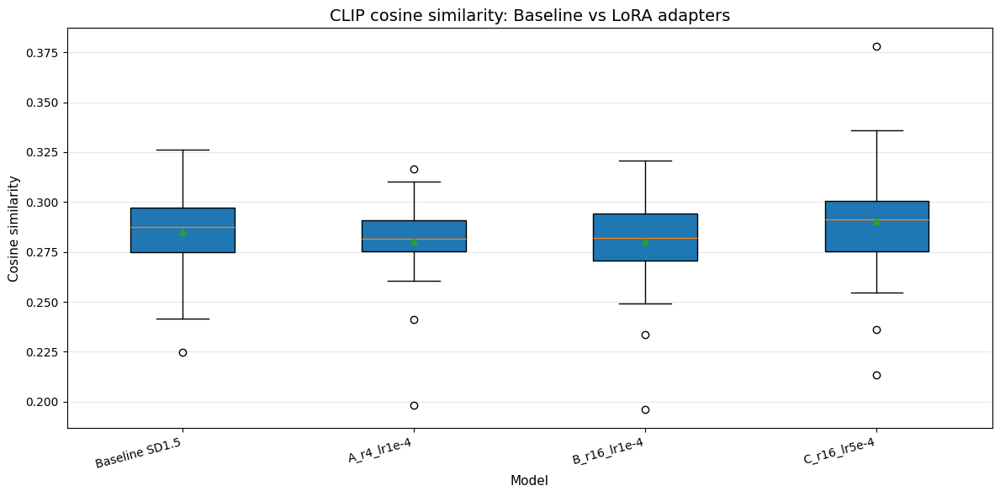


СРАВНЕНИЕ CLIP COSINE SIMILARITY
------------------------------------------------------------------------------------------
Baseline SD1.5            | mean=0.2852 | median=0.2873 | std=0.0206 | min=0.2246 | max=0.3264
A_r4_lr1e-4               | mean=0.2805 | median=0.2814 | std=0.0214 | min=0.1983 | max=0.3167
B_r16_lr1e-4              | mean=0.2802 | median=0.2822 | std=0.0238 | min=0.1959 | max=0.3207
C_r16_lr5e-4              | mean=0.2904 | median=0.2914 | std=0.0297 | min=0.2133 | max=0.3780

Boxplot сохранён: /content/drive/MyDrive/lab13/artifacts/full_run/task08_clip_boxplots.png


In [14]:
# ============================================================
# CLIP FEATURES И COSINE SIMILARITY
# ============================================================
import gc
import json
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from PIL import Image
from transformers import CLIPModel, CLIPProcessor
from pathlib import Path

assert 'GENERATION_RESULTS' in globals()
assert 'EVAL_CASES' in globals()
assert torch.cuda.is_available()

# ------------------------------------------------------------
# 1. Загрузка независимой CLIP-модели.
# ------------------------------------------------------------

CLIP_MODEL_ID = 'openai/clip-vit-large-patch14'

clip_processor = CLIPProcessor.from_pretrained(CLIP_MODEL_ID)

clip_model = CLIPModel.from_pretrained(
    CLIP_MODEL_ID
).to(DEVICE)

clip_model.eval()

for param in clip_model.parameters():
    param.requires_grad_(False)

print('CLIP model:', CLIP_MODEL_ID)
print('Device:', DEVICE)

# ------------------------------------------------------------
# 2. Функции получения нормализованных embeddings.
# ------------------------------------------------------------

@torch.inference_mode()
def get_clip_features(images, texts, batch_size=8):

    image_features_all = []
    text_features_all = []

    for start in range(0, len(images), batch_size):

        batch_images = images[start:start + batch_size]
        batch_texts = texts[start:start + batch_size]

        inputs = clip_processor(
            text=batch_texts,
            images=batch_images,
            return_tensors='pt',
            padding=True,
            truncation=True
        )

        inputs = {
            k: v.to(DEVICE)
            for k, v in inputs.items()
        }

        outputs = clip_model(**inputs)

        # Нормализация embeddings до единичной длины.
        image_features = F.normalize(
            outputs.image_embeds.float(),
            p=2,
            dim=-1
        )

        text_features = F.normalize(
            outputs.text_embeds.float(),
            p=2,
            dim=-1
        )

        image_features_all.append(
            image_features.cpu()
        )

        text_features_all.append(
            text_features.cpu()
        )

    return (
        torch.cat(image_features_all, dim=0),
        torch.cat(text_features_all, dim=0)
    )


# ------------------------------------------------------------
# 3. Расчёт embeddings для baseline и всех адаптеров.
# ------------------------------------------------------------

CLIP_RESULTS = {}
CLIP_EMBEDDINGS = {}

for model_name, model_data in GENERATION_RESULTS.items():

    print('\nОбработка:', model_data['label'])

    images = []
    texts = []
    case_ids = []

    for case in EVAL_CASES:

        case_id = case['case_id']
        image_path = model_data['images'][case_id]

        with Image.open(image_path) as im:
            images.append(im.convert('RGB').copy())

        texts.append(case['prompt'])
        case_ids.append(case_id)

    # Получаем embeddings.
    image_emb, text_emb = get_clip_features(
        images,
        texts,
        batch_size=8
    )

    # Проверка L2-нормализации.
    image_norms = torch.linalg.vector_norm(
        image_emb, dim=1
    )

    text_norms = torch.linalg.vector_norm(
        text_emb, dim=1
    )

    assert torch.allclose(
        image_norms,
        torch.ones_like(image_norms),
        atol=1e-5
    )

    assert torch.allclose(
        text_norms,
        torch.ones_like(text_norms),
        atol=1e-5
    )

    # Cosine similarity для каждой пары изображение-текст.
    similarities = torch.sum(
        image_emb * text_emb,
        dim=1
    )

    rows = []

    for i, case in enumerate(EVAL_CASES):

        rows.append({
            'case_id': case_ids[i],
            'prompt_id': case['prompt_id'],
            'group': case['group'],
            'seed': case['seed'],
            'prompt': case['prompt'],
            'image_path': model_data['images'][case_ids[i]],
            'cosine_similarity': float(similarities[i])
        })

    CLIP_RESULTS[model_name] = rows

    CLIP_EMBEDDINGS[model_name] = {
        'image_embeddings': image_emb.numpy(),
        'text_embeddings': text_emb.numpy()
    }

    print(
        f"Images: {len(rows)}, "
        f"similarity mean: {similarities.mean():.4f}, "
        f"std: {similarities.std():.4f}"
    )

# ------------------------------------------------------------
# 4. Проверка результата и сохранение embeddings.
# ------------------------------------------------------------

embedding_path = RUN_DIR / 'task08_clip_embeddings.npz'

embedding_arrays = {}

for name, emb in CLIP_EMBEDDINGS.items():

    embedding_arrays[f'{name}_image'] = emb['image_embeddings']
    embedding_arrays[f'{name}_text'] = emb['text_embeddings']

np.savez_compressed(
    embedding_path,
    **embedding_arrays
)

clip_report = {
    'status': 'passed',
    'model': CLIP_MODEL_ID,
    'embedding_dimension': int(
        next(iter(CLIP_EMBEDDINGS.values()))['image_embeddings'].shape[1]
    ),
    'normalized': True,
    'similarity': {
        name: {
            'mean': float(np.mean([
                r['cosine_similarity'] for r in rows
            ])),
            'std': float(np.std([
                r['cosine_similarity'] for r in rows
            ])),
            'min': float(np.min([
                r['cosine_similarity'] for r in rows
            ])),
            'max': float(np.max([
                r['cosine_similarity'] for r in rows
            ]))
        }
        for name, rows in CLIP_RESULTS.items()
    }
}

clip_json = RUN_DIR / 'task08_clip_metrics.json'

clip_json.write_text(
    json.dumps(clip_report, ensure_ascii=False, indent=2)
)

# Сохраняем подробные результаты по каждому изображению.
clip_details_path = RUN_DIR / 'task08_clip_details.json'

clip_details_path.write_text(
    json.dumps(CLIP_RESULTS, ensure_ascii=False, indent=2)
)

print('\nCLIP embeddings сохранены:', embedding_path)
print('Метрики сохранены:', clip_json)
print('Подробные результаты:', clip_details_path)

# ------------------------------------------------------------
# 5. Boxplots cosine similarity.
# ------------------------------------------------------------

model_names = list(CLIP_RESULTS.keys())

boxplot_data = [
    [
        row['cosine_similarity']
        for row in CLIP_RESULTS[name]
    ]
    for name in model_names
]

labels = [
    GENERATION_RESULTS[name]['label']
    for name in model_names
]

fig, ax = plt.subplots(figsize=(12, 6))

bp = ax.boxplot(
    boxplot_data,
    labels=labels,
    patch_artist=True,
    showmeans=True,
    showfliers=True
)

ax.set_title(
    'CLIP cosine similarity: Baseline vs LoRA adapters',
    fontsize=14
)

ax.set_ylabel('Cosine similarity', fontsize=11)
ax.set_xlabel('Model', fontsize=11)

ax.grid(axis='y', alpha=0.3)
plt.xticks(rotation=15, ha='right')

fig.tight_layout()

boxplot_path = RUN_DIR / 'task08_clip_boxplots.png'

fig.savefig(
    boxplot_path,
    dpi=160,
    bbox_inches='tight'
)

plt.show()

# ------------------------------------------------------------
# 6. Сводная таблица.
# ------------------------------------------------------------

print('\nСРАВНЕНИЕ CLIP COSINE SIMILARITY')
print('-' * 90)

for name in model_names:

    values = [
        r['cosine_similarity']
        for r in CLIP_RESULTS[name]
    ]

    print(
        f"{GENERATION_RESULTS[name]['label']:25s} | "
        f"mean={np.mean(values):.4f} | "
        f"median={np.median(values):.4f} | "
        f"std={np.std(values):.4f} | "
        f"min={np.min(values):.4f} | "
        f"max={np.max(values):.4f}"
    )

print('\nBoxplot сохранён:', boxplot_path)

# Освобождаем GPU.
del clip_model, clip_processor
gc.collect()
torch.cuda.empty_cache()

# Для следующего этапа:
# CLIP_RESULTS — similarity и метаданные изображений.
# CLIP_EMBEDDINGS — нормализованные embeddings.



МОДЕЛЬ: Baseline SD1.5


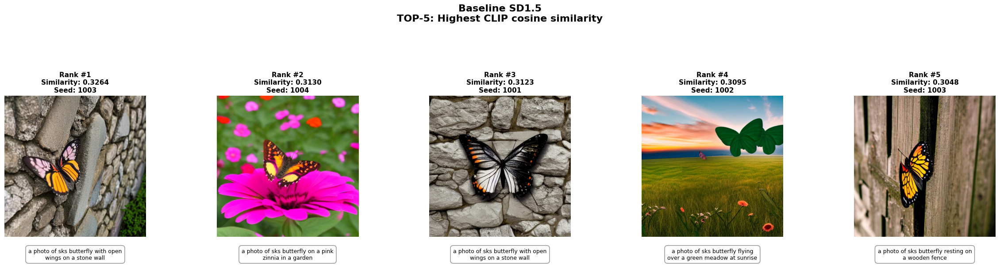

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/baseline_best_top5.png


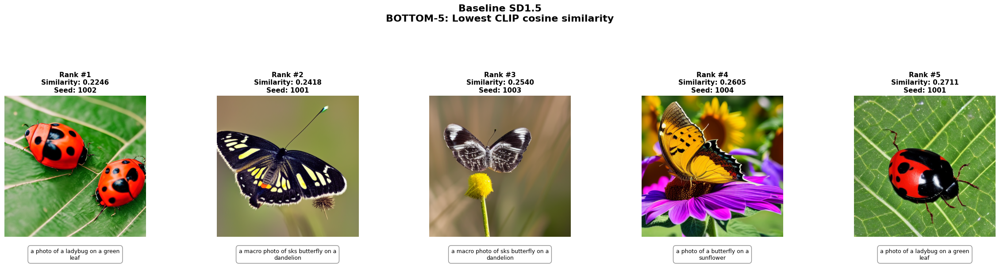

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/baseline_worst_top5.png

МОДЕЛЬ: A_r4_lr1e-4


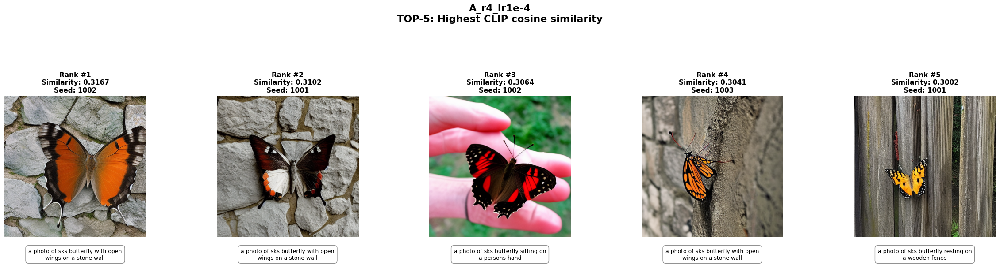

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/A_r4_lr1e-4_best_top5.png


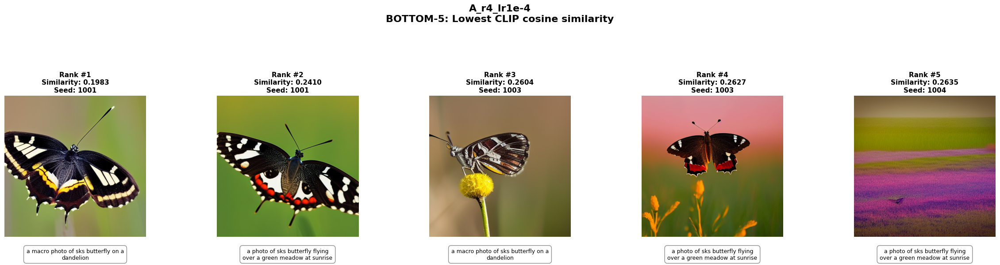

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/A_r4_lr1e-4_worst_top5.png

МОДЕЛЬ: B_r16_lr1e-4


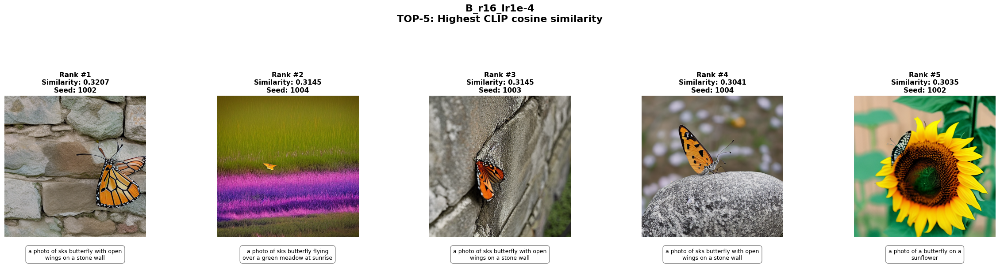

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/B_r16_lr1e-4_best_top5.png


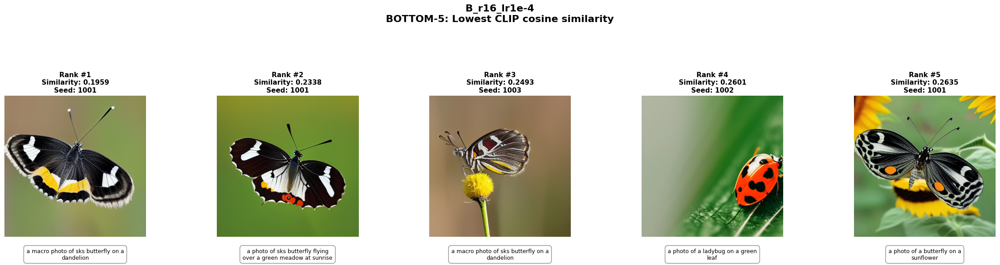

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/B_r16_lr1e-4_worst_top5.png

МОДЕЛЬ: C_r16_lr5e-4


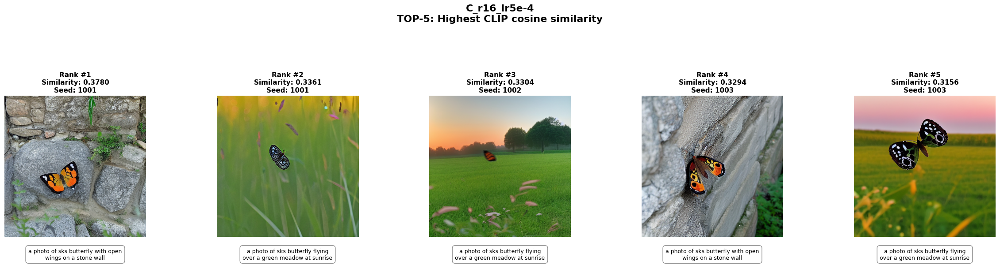

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/C_r16_lr5e-4_best_top5.png


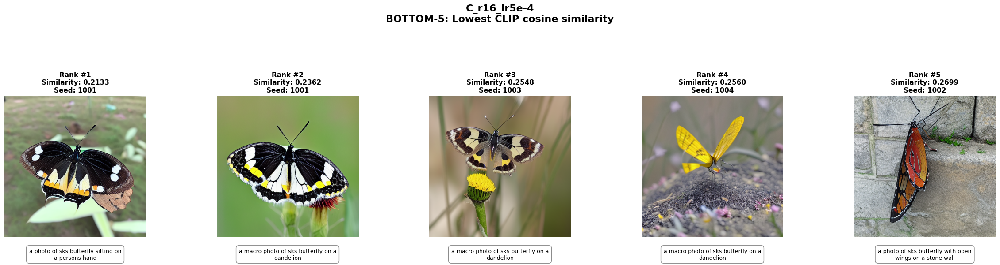

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/C_r16_lr5e-4_worst_top5.png
baseline: best=0.3264, worst=0.2246
A_r4_lr1e-4: best=0.3167, worst=0.1983
B_r16_lr1e-4: best=0.3207, worst=0.1959
C_r16_lr5e-4: best=0.3780, worst=0.2133

ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА
Результаты: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst
JSON: /content/drive/MyDrive/lab13/artifacts/full_run/task09_best_worst/task09_ranking_results.json
Количество моделей: 4
Всего визуализаций: 8


In [15]:
# ============================================================
# TOP-5 / BOTTOM-5 ПО CLIP COSINE SIMILARITY
# ============================================================
import matplotlib.pyplot as plt
import textwrap
import json
from PIL import Image
from pathlib import Path

assert 'CLIP_RESULTS' in globals()
assert 'GENERATION_RESULTS' in globals()

VISUALIZATION_DIR = RUN_DIR / 'task09_best_worst'
VISUALIZATION_DIR.mkdir(parents=True, exist_ok=True)

TOP_K = 5

# ------------------------------------------------------------
# 1. Функция визуализации.
# ------------------------------------------------------------

def visualize_ranked_images(
    model_name,
    rows,
    ranking='best',
    top_k=5
):
    """
    ranking='best'  — максимальная cosine similarity.
    ranking='worst' — минимальная cosine similarity.
    """

    if ranking == 'best':
        selected = sorted(
            rows,
            key=lambda x: x['cosine_similarity'],
            reverse=True
        )[:top_k]

        title = 'TOP-5: Highest CLIP cosine similarity'

    else:
        selected = sorted(
            rows,
            key=lambda x: x['cosine_similarity']
        )[:top_k]

        title = 'BOTTOM-5: Lowest CLIP cosine similarity'

    fig, axes = plt.subplots(
        1,
        len(selected),
        figsize=(24, 8),
        squeeze=False
    )

    axes = axes.ravel()

    for rank, (ax, item) in enumerate(
        zip(axes, selected), start=1
    ):

        image_path = item['image_path']

        with Image.open(image_path) as im:
            ax.imshow(im.convert('RGB'))

        score = item['cosine_similarity']

        # Заголовок с рангом и similarity.
        ax.set_title(
            f"Rank #{rank}\n"
            f"Similarity: {score:.4f}\n"
            f"Seed: {item['seed']}",
            fontsize=11,
            fontweight='bold'
        )

        ax.axis('off')

        # Полный prompt под изображением.
        prompt = item['prompt']

        wrapped_prompt = textwrap.fill(
            prompt,
            width=35
        )

        ax.text(
            0.5,
            -0.08,
            wrapped_prompt,
            transform=ax.transAxes,
            ha='center',
            va='top',
            fontsize=9,
            wrap=True,
            bbox=dict(
                boxstyle='round,pad=0.5',
                facecolor='white',
                edgecolor='gray',
                alpha=0.9
            ),
            clip_on=False
        )

    fig.suptitle(
        f"{GENERATION_RESULTS[model_name]['label']}\n{title}",
        fontsize=16,
        fontweight='bold',
        y=1.04
    )

    # Большое пространство под полные подписи.
    fig.subplots_adjust(
        left=0.02,
        right=0.98,
        top=0.78,
        bottom=0.38,
        wspace=0.25
    )

    filename = f'{model_name}_{ranking}_top{top_k}.png'

    save_path = VISUALIZATION_DIR / filename

    fig.savefig(
        save_path,
        dpi=180,
        bbox_inches='tight'
    )

    plt.show()

    plt.close(fig)

    print('Сохранено:', save_path)

    return [
        {
            'rank': rank,
            'case_id': item['case_id'],
            'prompt': item['prompt'],
            'seed': item['seed'],
            'cosine_similarity': item['cosine_similarity'],
            'image_path': item['image_path']
        }
        for rank, item in enumerate(selected, start=1)
    ]


# ------------------------------------------------------------
# 2. Визуализация для baseline и трёх адаптеров.
# ------------------------------------------------------------

RANKING_RESULTS = {}

for model_name in CLIP_RESULTS:

    print('\n' + '=' * 90)
    print('МОДЕЛЬ:', GENERATION_RESULTS[model_name]['label'])
    print('=' * 90)

    rows = CLIP_RESULTS[model_name]

    # Пять лучших.
    best = visualize_ranked_images(
        model_name=model_name,
        rows=rows,
        ranking='best',
        top_k=TOP_K
    )

    # Пять худших.
    worst = visualize_ranked_images(
        model_name=model_name,
        rows=rows,
        ranking='worst',
        top_k=TOP_K
    )

    RANKING_RESULTS[model_name] = {
        'best_5': best,
        'worst_5': worst
    }


# ------------------------------------------------------------
# 3. Сохранение результатов ранжирования.
# ------------------------------------------------------------

ranking_json = VISUALIZATION_DIR / 'task09_ranking_results.json'

ranking_json.write_text(
    json.dumps(
        RANKING_RESULTS,
        ensure_ascii=False,
        indent=2
    )
)

# ------------------------------------------------------------
# 4. Итоговая проверка.
# ------------------------------------------------------------

for model_name, result in RANKING_RESULTS.items():

    assert len(result['best_5']) == TOP_K
    assert len(result['worst_5']) == TOP_K

    best_scores = [
        x['cosine_similarity']
        for x in result['best_5']
    ]

    worst_scores = [
        x['cosine_similarity']
        for x in result['worst_5']
    ]

    assert best_scores == sorted(
        best_scores,
        reverse=True
    )

    assert worst_scores == sorted(
        worst_scores
    )

    print(
        f"{model_name}: "
        f"best={best_scores[0]:.4f}, "
        f"worst={worst_scores[0]:.4f}"
    )

print('\n' + '=' * 90)
print('ВИЗУАЛИЗАЦИЯ ЗАВЕРШЕНА')
print('=' * 90)

print('Результаты:', VISUALIZATION_DIR)
print('JSON:', ranking_json)
print('Количество моделей:', len(RANKING_RESULTS))
print('Всего визуализаций:', len(RANKING_RESULTS) * 2)


### Поиск ближайших обучающих изображений

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки.

**Результат.** Проверяемое состояние «Поиск ближайших обучающих изображений» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Вычислите эмбеддинги реальных train изображений и зафиксируйте набор checkpoint для оценки» и его результат доступен следующему этапу.

In [16]:
# Train image embeddings + checkpoint manifest
import gc, json
from pathlib import Path
import numpy as np
import torch
import torch.nn.functional as F
from PIL import Image
from transformers import CLIPModel, CLIPProcessor

assert 'TRAIN_RECORDS' in globals() and len(TRAIN_RECORDS) > 0
assert 'LORA_DATA' in globals() and 'RUN_DIR' in globals()
assert 'GENERATION_RESULTS' in globals(), (
    "Сначала должна быть выполнена ячейка с уже существующими генерациями"
)
assert torch.cuda.is_available(), "Для этого эксперимента требуется GPU"

TASK10_DIR = RUN_DIR / 'task10_train_embeddings'
TASK10_DIR.mkdir(parents=True, exist_ok=True)

CLIP_ID = 'openai/clip-vit-large-patch14'
clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()
clip_model.requires_grad_(False)

# 1. Фиксируем train-набор и его порядок
train_manifest = []
train_images = []

for i, rec in enumerate(TRAIN_RECORDS):
    path = LORA_DATA / rec['file_name']
    assert path.is_file(), f"Не найден train-файл: {path}"
    with Image.open(path) as im:
        train_images.append(im.convert('RGB').copy())
    train_manifest.append({
        'index': i,
        'file_name': rec['file_name'],
        'caption': rec['text'],
        'sha256': rec['sha256'],
        'path': str(path)
    })

# 2. Получаем нормированные CLIP image embeddings
train_emb_batches = []

with torch.inference_mode():
    for start in range(0, len(train_images), 8):
        batch = train_images[start:start + 8]

        inputs = clip_processor(images=batch, return_tensors='pt')
        inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

        # Совместимо с версиями transformers,
        # где get_image_features возвращает объект encoder output
        vision_outputs = clip_model.vision_model(
            pixel_values=inputs['pixel_values'],
            return_dict=True
        )

        pooled = vision_outputs.pooler_output
        emb = clip_model.visual_projection(pooled)

        emb = F.normalize(emb.float(), p=2, dim=-1)
        train_emb_batches.append(emb.cpu())

TRAIN_CLIP_EMBEDDINGS = torch.cat(train_emb_batches, dim=0).numpy()

assert TRAIN_CLIP_EMBEDDINGS.shape[0] == len(TRAIN_RECORDS)
assert np.isfinite(TRAIN_CLIP_EMBEDDINGS).all()
assert np.allclose(
    np.linalg.norm(TRAIN_CLIP_EMBEDDINGS, axis=1), 1.0, atol=1e-4
)

print("Train embeddings:", TRAIN_CLIP_EMBEDDINGS.shape)

# 3. Фиксируем checkpoint для каждой модели из уже готовых генераций
checkpoint_manifest = {}

for model_name in GENERATION_RESULTS:
    if model_name == 'baseline':
        checkpoint_manifest[model_name] = {
            'type': 'base_model',
            'lora': False,
            'checkpoint': None,
            'note': 'Чистая SD1.5 без LoRA'
        }
        continue

    adapter_dir = ADAPTER_ROOT / model_name
    complete_ckpts = sorted(
        [
            p for p in adapter_dir.glob('checkpoint-*')
            if (p / 'COMPLETE').exists()
            and (p / 'pytorch_lora_weights.safetensors').exists()
        ],
        key=lambda p: int(p.name.split('-')[-1])
    )
    assert complete_ckpts, f"Для {model_name} не найден завершённый checkpoint"

    selected = complete_ckpts[-1]
    meta_path = selected / 'meta.json'
    meta = json.loads(meta_path.read_text()) if meta_path.exists() else {}

    checkpoint_manifest[model_name] = {
        'type': 'lora_adapter',
        'lora': True,
        'checkpoint': str(selected),
        'update': int(selected.name.split('-')[-1]),
        'weights_file': str(selected / 'pytorch_lora_weights.safetensors'),
        'weights_sha256': meta.get('weights_sha256'),
        'config_fingerprint': meta.get('config_fingerprint'),
        'dataset_fingerprint': meta.get('dataset_fingerprint')
    }

# Проверяем, что для каждой модели действительно есть готовые генерации
for model_name, info in GENERATION_RESULTS.items():
    images = info['images']
    assert images, f"Нет генераций для {model_name}"
    for case_id, path in images.items():
        assert Path(path).is_file(), f"Нет файла генерации: {model_name}/{case_id}"

# 4. Сохраняем артефакты для следующего этапа
np.savez_compressed(
    TASK10_DIR / 'task10_train_clip_embeddings.npz',
    embeddings=TRAIN_CLIP_EMBEDDINGS
)

(TASK10_DIR / 'task10_train_manifest.json').write_text(
    json.dumps(train_manifest, ensure_ascii=False, indent=2)
)

(TASK10_DIR / 'task10_checkpoint_manifest.json').write_text(
    json.dumps(checkpoint_manifest, ensure_ascii=False, indent=2)
)

task10_report = {
    'status': 'passed',
    'clip_model': CLIP_ID,
    'n_train_images': len(train_manifest),
    'embedding_shape': list(TRAIN_CLIP_EMBEDDINGS.shape),
    'embedding_normalized': True,
    'models': list(GENERATION_RESULTS.keys()),
    'checkpoint_manifest': checkpoint_manifest,
    'generation_images_per_model': {
        name: len(info['images'])
        for name, info in GENERATION_RESULTS.items()
    },
    'artifacts': [
        str(TASK10_DIR / 'task10_train_clip_embeddings.npz'),
        str(TASK10_DIR / 'task10_train_manifest.json'),
        str(TASK10_DIR / 'task10_checkpoint_manifest.json')
    ]
}

(TASK10_DIR / 'task10_report.json').write_text(
    json.dumps(task10_report, ensure_ascii=False, indent=2)
)

print("Задание 10:", task10_report['status'])
print("Train images:", len(train_manifest))
print("Embedding shape:", TRAIN_CLIP_EMBEDDINGS.shape)
for name, info in checkpoint_manifest.items():
    print(name, "->", info['checkpoint'] or "BASELINE: без LoRA")

del clip_model, clip_processor, train_images
gc.collect()
torch.cuda.empty_cache()

TRAIN_CLIP_EMBEDDINGS  # остаётся доступным в памяти следующей ячейке

Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Train embeddings: (28, 768)
Задание 10: passed
Train images: 28
Embedding shape: (28, 768)
baseline -> BASELINE: без LoRA
A_r4_lr1e-4 -> /content/drive/MyDrive/lab13/artifacts/full_run/adapters/A_r4_lr1e-4/checkpoint-0400
B_r16_lr1e-4 -> /content/drive/MyDrive/lab13/artifacts/full_run/adapters/B_r16_lr1e-4/checkpoint-0400
C_r16_lr5e-4 -> /content/drive/MyDrive/lab13/artifacts/full_run/adapters/C_r16_lr5e-4/checkpoint-0400


array([[ 0.02392834,  0.02887801, -0.01022345, ...,  0.01174357,
         0.02956911, -0.0064455 ],
       [-0.03535466,  0.03608738,  0.01441515, ..., -0.0053695 ,
        -0.00594484, -0.00037806],
       [-0.04213591, -0.00663729,  0.03229326, ...,  0.02003091,
        -0.04235183,  0.02624056],
       ...,
       [-0.02808172,  0.03236088,  0.01369962, ..., -0.0027554 ,
         0.02813921, -0.01205783],
       [ 0.00517892,  0.03633316,  0.00685789, ..., -0.00805112,
        -0.01311095,  0.01392203],
       [-0.03038818,  0.04921494, -0.00245752, ..., -0.00797736,
        -0.00599588,  0.00478302]], shape=(28, 768), dtype=float32)

### Парные генерации и измеримые показатели

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA.

**Результат.** Проверяемое состояние «Парные генерации и измеримые показатели» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Для равных prompts/seeds измерьте текстовое сходство, разнообразие и ближайший train объект; baseline не должен содержать LoRA» и его результат доступен следующему этапу.

Модели: ['baseline', 'A_r4_lr1e-4', 'B_r16_lr1e-4', 'C_r16_lr5e-4']
Изображений на модель: 32


Loading weights:   0%|          | 0/590 [00:00<?, ?it/s]

Train embeddings: (28, 768)

Сводные метрики:

baseline
  clip_text_similarity: mean=0.28515995433554053, std=0.020919351331251328, n=32
  diversity: mean=0.09708985453471541, std=0.03779991382695162, n=8
  memorization_similarity: mean=0.8358433600515127, std=0.04645994210677702, n=32

A_r4_lr1e-4
  clip_text_similarity: mean=0.280548345297575, std=0.021721512814899216, n=32
  diversity: mean=0.11120845563709736, std=0.055320188355524456, n=8
  memorization_similarity: mean=0.8474896363914013, std=0.039366659672933305, n=32

B_r16_lr1e-4
  clip_text_similarity: mean=0.2801604741252959, std=0.024134086049745714, n=32
  diversity: mean=0.11309385299682617, std=0.05538005924633523, n=8
  memorization_similarity: mean=0.8518711384385824, std=0.041210428395793613, n=32

C_r16_lr5e-4
  clip_text_similarity: mean=0.2904102560132742, std=0.030190969282934806, n=32
  diversity: mean=0.12839349871501327, std=0.057863281590233955, n=8
  memorization_similarity: mean=0.8422408271580935, std=0.042

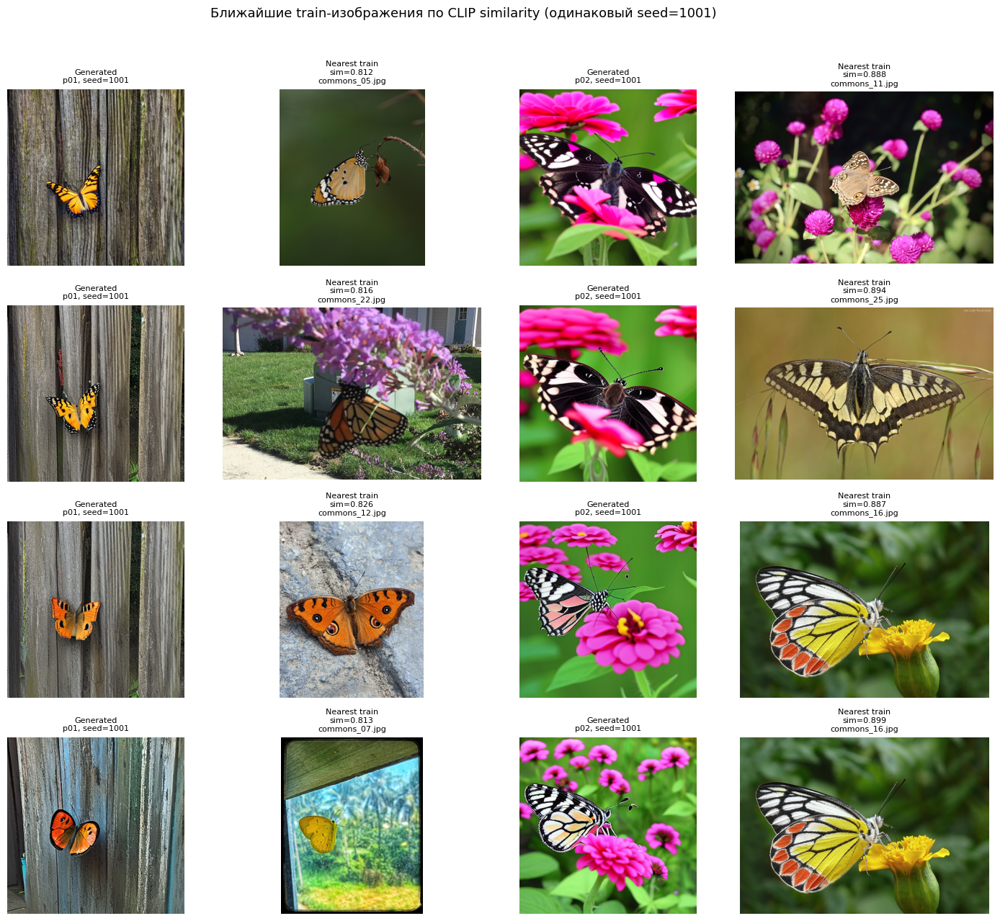

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task11_nearest_train_visualization.png


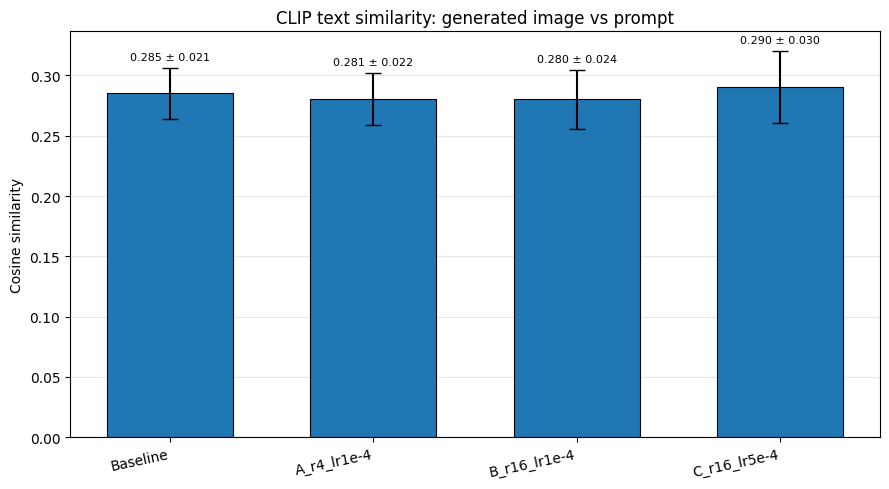

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task11_hist_clip_text_similarity.png


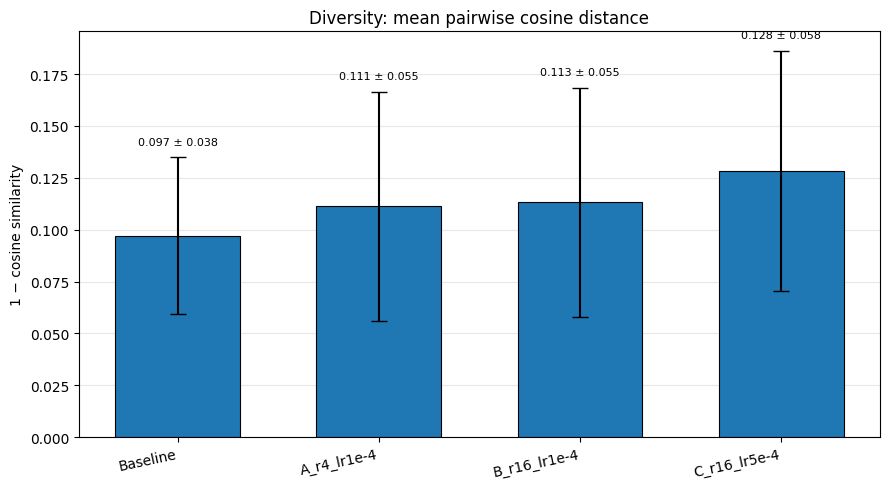

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task11_hist_diversity.png


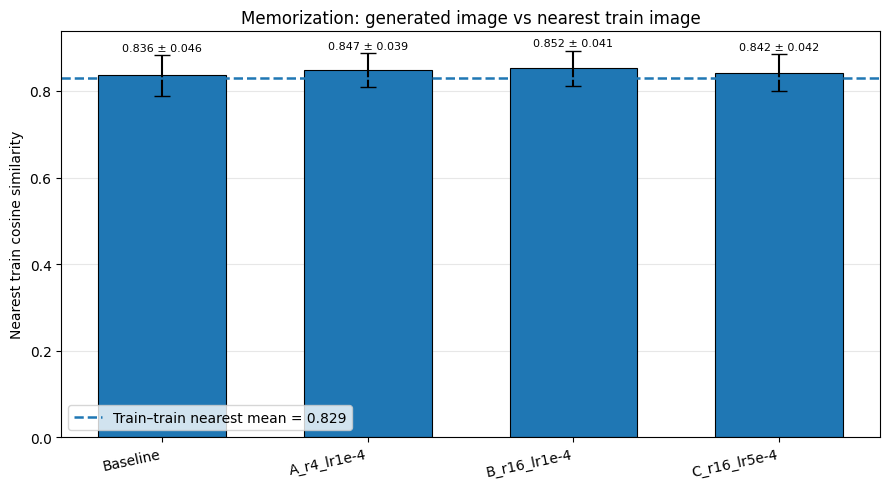

Сохранено: /content/drive/MyDrive/lab13/artifacts/full_run/task11_hist_memorization_similarity.png

Задание 11 завершено.
Результаты сохранены в: /content/drive/MyDrive/lab13/artifacts/full_run


In [17]:
# ============================================================
# CLIP-МЕТРИКИ, БЛИЖАЙШИЕ TRAIN-ИЗОБРАЖЕНИЯ И ГРАФИКИ
# ============================================================
import gc
import json
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path
from PIL import Image
from transformers import CLIPProcessor, CLIPModel

# ------------------------------------------------------------
# 0. Проверка входных данных
# ------------------------------------------------------------

required = [
    'EVAL_CASES', 'GENERATION_RESULTS', 'BASELINE',
    'TRAIN_RECORDS', 'LORA_DATA', 'LORA_CONFIGS',
    'CLIP_ID', 'DEVICE', 'RUN_DIR'
]
missing = [x for x in required if x not in globals()]
assert not missing, f'Сначала выполните предыдущие задания. Нет переменных: {missing}'

assert len(LORA_CONFIGS) == 3, (
    f'Ожидаются ровно 3 адаптера, найдено: {len(LORA_CONFIGS)}'
)

MODEL_NAMES = ['baseline'] + [cfg['name'] for cfg in LORA_CONFIGS]
MODEL_LABELS = ['Baseline'] + [cfg['name'] for cfg in LORA_CONFIGS]

# ------------------------------------------------------------
# 1. Собираем пути к уже существующим изображениям
# ------------------------------------------------------------

def get_image_mapping(value):
    """Поддерживает как {'images': {...}}, так и непосредственный словарь путей."""
    if isinstance(value, dict) and 'images' in value:
        return value['images']
    return value


generation_paths = {}

# Baseline
if 'baseline' in GENERATION_RESULTS:
    generation_paths['baseline'] = get_image_mapping(
        GENERATION_RESULTS['baseline']
    )
else:
    generation_paths['baseline'] = BASELINE

# Три адаптера
for cfg in LORA_CONFIGS:
    name = cfg['name']
    assert name in GENERATION_RESULTS, (
        f'Нет сохранённых генераций для адаптера {name!r}. '
        'Сначала выполните этап генерации адаптеров.'
    )
    generation_paths[name] = get_image_mapping(GENERATION_RESULTS[name])

# Приводим пути к Path и проверяем файлы
case_ids = [c['case_id'] for c in EVAL_CASES]
case_by_id = {c['case_id']: c for c in EVAL_CASES}

for model_name in MODEL_NAMES:
    mapping = generation_paths[model_name]
    absent = [cid for cid in case_ids if cid not in mapping]
    assert not absent, (
        f'{model_name}: отсутствуют результаты для case_id: {absent}'
    )

    for cid in case_ids:
        p = Path(mapping[cid])
        assert p.is_file(), f'Не найден файл генерации: {p}'
        mapping[cid] = p

print('Модели:', MODEL_NAMES)
print('Изображений на модель:', len(case_ids))

# ------------------------------------------------------------
# 2. Загружаем CLIP
# ------------------------------------------------------------

clip_processor = CLIPProcessor.from_pretrained(CLIP_ID)
clip_model = CLIPModel.from_pretrained(CLIP_ID).to(DEVICE).eval()

def encode_images_clip(images, batch_size=8):
    """
    CLIP image embeddings.
    Используем vision_model + visual_projection напрямую:
    это совместимо с версиями transformers, где get_image_features()
    возвращает BaseModelOutputWithPooling.
    """
    all_embeddings = []

    with torch.inference_mode():
        for start in range(0, len(images), batch_size):
            batch = images[start:start + batch_size]

            inputs = clip_processor(
                images=batch,
                return_tensors='pt'
            )
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

            outputs = clip_model.vision_model(
                pixel_values=inputs['pixel_values'],
                return_dict=True
            )
            features = clip_model.visual_projection(
                outputs.pooler_output
            )
            features = F.normalize(features.float(), p=2, dim=-1)

            all_embeddings.append(features.cpu())

    return torch.cat(all_embeddings, dim=0)


def encode_texts_clip(texts, batch_size=16):
    """CLIP text embeddings с прямым вызовом text_model."""
    all_embeddings = []

    with torch.inference_mode():
        for start in range(0, len(texts), batch_size):
            batch = texts[start:start + batch_size]

            inputs = clip_processor(
                text=batch,
                padding=True,
                truncation=True,
                return_tensors='pt'
            )
            inputs = {k: v.to(DEVICE) for k, v in inputs.items()}

            outputs = clip_model.text_model(
                input_ids=inputs['input_ids'],
                attention_mask=inputs.get('attention_mask'),
                return_dict=True
            )
            features = clip_model.text_projection(
                outputs.pooler_output
            )
            features = F.normalize(features.float(), p=2, dim=-1)

            all_embeddings.append(features.cpu())

    return torch.cat(all_embeddings, dim=0)


# ------------------------------------------------------------
# 3. Загружаем train images и вычисляем embeddings
# ------------------------------------------------------------

train_paths = [
    Path(LORA_DATA) / record['file_name']
    for record in TRAIN_RECORDS
]

for p in train_paths:
    assert p.is_file(), f'Не найден train-файл: {p}'

train_images = []
for p in train_paths:
    with Image.open(p) as im:
        train_images.append(im.convert('RGB').copy())

TRAIN_CLIP_EMBEDDINGS = encode_images_clip(train_images).numpy()
TRAIN_CLIP_EMBEDDINGS = TRAIN_CLIP_EMBEDDINGS / np.maximum(
    np.linalg.norm(TRAIN_CLIP_EMBEDDINGS, axis=1, keepdims=True), 1e-12
)

print('Train embeddings:', TRAIN_CLIP_EMBEDDINGS.shape)

# ------------------------------------------------------------
# 4. Вычисляем embeddings всех сохранённых генераций
# ------------------------------------------------------------

all_generated_images = {}
all_generated_embeddings = {}

for model_name in MODEL_NAMES:
    images = []

    for cid in case_ids:
        with Image.open(generation_paths[model_name][cid]) as im:
            images.append(im.convert('RGB').copy())

    all_generated_images[model_name] = images
    all_generated_embeddings[model_name] = encode_images_clip(images).numpy()

    # Нормализация на случай изменения поведения API
    emb = all_generated_embeddings[model_name]
    all_generated_embeddings[model_name] = emb / np.maximum(
        np.linalg.norm(emb, axis=1, keepdims=True), 1e-12
    )

# Текстовые embeddings: по одному на каждый уникальный prompt
prompt_ids = list(dict.fromkeys(c['prompt_id'] for c in EVAL_CASES))
prompt_texts = [
    next(c['prompt'] for c in EVAL_CASES if c['prompt_id'] == pid)
    for pid in prompt_ids
]
prompt_embeddings = encode_texts_clip(prompt_texts).numpy()
prompt_embeddings = prompt_embeddings / np.maximum(
    np.linalg.norm(prompt_embeddings, axis=1, keepdims=True), 1e-12
)
prompt_embedding_by_id = dict(zip(prompt_ids, prompt_embeddings))

case_index = {cid: i for i, cid in enumerate(case_ids)}

# ------------------------------------------------------------
# 5. Метрики для каждой модели
# ------------------------------------------------------------

# Train -> train nearest-neighbor similarity.
# Диагональ исключается, чтобы изображение не сравнивалось само с собой.
train_similarity_matrix = (
    TRAIN_CLIP_EMBEDDINGS @ TRAIN_CLIP_EMBEDDINGS.T
)
np.fill_diagonal(train_similarity_matrix, -np.inf)

train_train_nearest = train_similarity_matrix.max(axis=1)
TRAIN_TRAIN_MEAN = float(train_train_nearest.mean())
TRAIN_TRAIN_STD = float(train_train_nearest.std(ddof=1)) if len(train_train_nearest) > 1 else 0.0

metrics = {}
nearest_records = {}

for model_name in MODEL_NAMES:
    generated_emb = all_generated_embeddings[model_name]

    # Генерация -> train similarity
    sim_to_train = generated_emb @ TRAIN_CLIP_EMBEDDINGS.T
    nearest_train_idx = sim_to_train.argmax(axis=1)
    nearest_train_sim = sim_to_train.max(axis=1)

    # CLIP text similarity: image embedding vs embedding своего prompt
    text_sims = []
    memorization_sims = []
    nearest_rows = []

    for cid in case_ids:
        i = case_index[cid]
        case = case_by_id[cid]

        text_emb = prompt_embedding_by_id[case['prompt_id']]
        text_sim = float(generated_emb[i] @ text_emb)

        train_idx = int(nearest_train_idx[i])
        train_sim = float(nearest_train_sim[i])

        text_sims.append(text_sim)
        memorization_sims.append(train_sim)

        nearest_rows.append({
            'case_id': cid,
            'prompt_id': case['prompt_id'],
            'seed': int(case['seed']),
            'generated_path': str(generation_paths[model_name][cid]),
            'nearest_train_file': TRAIN_RECORDS[train_idx]['file_name'],
            'nearest_train_path': str(train_paths[train_idx]),
            'nearest_train_similarity': train_sim
        })

    # Diversity:
    # для каждого prompt считаем среднее попарное cosine distance
    # между генерациями с разными seeds.
    diversity_by_prompt = []

    for pid in prompt_ids:
        prompt_case_ids = [
            c['case_id'] for c in EVAL_CASES
            if c['prompt_id'] == pid
        ]
        indices = [case_index[cid] for cid in prompt_case_ids]

        if len(indices) < 2:
            # При одном seed diversity математически не оценивается.
            continue

        group_emb = generated_emb[indices]
        pairwise_sim = group_emb @ group_emb.T

        upper = pairwise_sim[np.triu_indices(len(indices), k=1)]
        pairwise_distance = 1.0 - upper

        diversity_by_prompt.append(float(pairwise_distance.mean()))

    metrics[model_name] = {
        'clip_text_similarity': np.asarray(text_sims, dtype=float),
        'memorization_similarity': np.asarray(memorization_sims, dtype=float),
        'diversity': np.asarray(diversity_by_prompt, dtype=float),
        'diversity_prompt_ids': [
            pid for pid in prompt_ids
            if sum(c['prompt_id'] == pid for c in EVAL_CASES) >= 2
        ]
    }

    nearest_records[model_name] = nearest_rows


# ------------------------------------------------------------
# 6. Таблица сводных значений
# ------------------------------------------------------------

def mean_std(values):
    values = np.asarray(values, dtype=float)
    values = values[np.isfinite(values)]

    if len(values) == 0:
        return None, None

    mean = float(values.mean())
    std = float(values.std(ddof=1)) if len(values) > 1 else 0.0
    return mean, std


summary = {}

for model_name in MODEL_NAMES:
    summary[model_name] = {}

    for metric_name in [
        'clip_text_similarity',
        'diversity',
        'memorization_similarity'
    ]:
        mean, std = mean_std(metrics[model_name][metric_name])
        summary[model_name][metric_name] = {
            'mean': mean,
            'std': std,
            'n': int(len(metrics[model_name][metric_name]))
        }

print('\nСводные метрики:')
for model_name in MODEL_NAMES:
    print(f'\n{model_name}')
    for metric_name, values in summary[model_name].items():
        print(
            f"  {metric_name}: "
            f"mean={values['mean']}, std={values['std']}, n={values['n']}"
        )

print(
    '\nTrain-train nearest similarity: '
    f'mean={TRAIN_TRAIN_MEAN:.4f}, std={TRAIN_TRAIN_STD:.4f}'
)

# ------------------------------------------------------------
# 7. Визуализация ближайших train-изображений
#    4 строки: baseline + 3 адаптера
#    2 примера на модель, одинаковые prompt и seed
# ------------------------------------------------------------

common_seeds = sorted(set(c['seed'] for c in EVAL_CASES))
assert common_seeds, 'В EVAL_CASES нет seed.'

VIS_SEED = common_seeds[0]

# Берём первые два prompt, для которых есть выбранный seed
visual_cases = [
    c for c in EVAL_CASES if c['seed'] == VIS_SEED
][:2]

assert len(visual_cases) == 2, (
    'Для визуализации нужны минимум два prompt для одного seed. '
    'В FAST_DEV_RUN может быть доступен только один prompt.'
)

fig, axes = plt.subplots(
    nrows=4,
    ncols=4,
    figsize=(15, 13)
)

for row, model_name in enumerate(MODEL_NAMES):
    for col_pair, case in enumerate(visual_cases):
        cid = case['case_id']
        i = case_index[cid]

        nearest = nearest_records[model_name][i]
        generated_path = generation_paths[model_name][cid]
        nearest_path = Path(nearest['nearest_train_path'])

        ax_gen = axes[row, col_pair * 2]
        ax_train = axes[row, col_pair * 2 + 1]

        with Image.open(generated_path) as im:
            ax_gen.imshow(im.convert('RGB'))
        ax_gen.set_title(
            f"Generated\n{case['prompt_id']}, seed={VIS_SEED}",
            fontsize=8
        )
        ax_gen.axis('off')

        with Image.open(nearest_path) as im:
            ax_train.imshow(im.convert('RGB'))
        ax_train.set_title(
            'Nearest train\n'
            f"sim={nearest['nearest_train_similarity']:.3f}\n"
            f"{Path(nearest['nearest_train_file']).name[:22]}",
            fontsize=8
        )
        ax_train.axis('off')

    axes[row, 0].set_ylabel(
        MODEL_LABELS[row],
        fontsize=11,
        rotation=90,
        labelpad=12
    )

fig.suptitle(
    f'Ближайшие train-изображения по CLIP similarity '
    f'(одинаковый seed={VIS_SEED})',
    fontsize=13
)
fig.tight_layout(rect=[0.03, 0, 1, 0.96])

nearest_grid_path = RUN_DIR / 'task11_nearest_train_visualization.png'
fig.savefig(nearest_grid_path, dpi=150, bbox_inches='tight')
plt.show()

print('Сохранено:', nearest_grid_path)

# ------------------------------------------------------------
# 8. Три графика: 4 столбца, среднее и std
# ------------------------------------------------------------

def plot_metric_bars(metric_key, title, ylabel, filename,
                     train_train_line=False):
    means = []
    stds = []

    for model_name in MODEL_NAMES:
        mean, std = mean_std(metrics[model_name][metric_key])
        means.append(np.nan if mean is None else mean)
        stds.append(0.0 if std is None else std)

    x = np.arange(len(MODEL_NAMES))

    fig, ax = plt.subplots(figsize=(9, 5))

    ax.bar(
        x,
        means,
        yerr=stds,
        capsize=6,
        width=0.62,
        edgecolor='black',
        linewidth=0.8
    )

    ax.set_xticks(x)
    ax.set_xticklabels(MODEL_LABELS, rotation=12, ha='right')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.grid(axis='y', alpha=0.3)
    ax.set_axisbelow(True)

    # Для memorization добавляем ориентир train-train
    if train_train_line:
        ax.axhline(
            TRAIN_TRAIN_MEAN,
            linestyle='--',
            linewidth=1.8,
            label=f'Train–train nearest mean = {TRAIN_TRAIN_MEAN:.3f}'
        )
        ax.legend()

    # Подписываем средние значения над столбцами
    finite_means = [v for v in means if np.isfinite(v)]
    if finite_means:
        spread = max(finite_means) - min(finite_means)
        offset = max(spread * 0.025, 0.005)

        for xi, mean, std in zip(x, means, stds):
            if np.isfinite(mean):
                ax.text(
                    xi,
                    mean + std + offset,
                    f'{mean:.3f} ± {std:.3f}',
                    ha='center',
                    va='bottom',
                    fontsize=8
                )

    fig.tight_layout()

    output_path = RUN_DIR / filename
    fig.savefig(output_path, dpi=150, bbox_inches='tight')
    plt.show()

    print('Сохранено:', output_path)


# График 1. CLIP text similarity
plot_metric_bars(
    metric_key='clip_text_similarity',
    title='CLIP text similarity: generated image vs prompt',
    ylabel='Cosine similarity',
    filename='task11_hist_clip_text_similarity.png'
)

# График 2. Diversity
plot_metric_bars(
    metric_key='diversity',
    title='Diversity: mean pairwise cosine distance',
    ylabel='1 − cosine similarity',
    filename='task11_hist_diversity.png'
)

# График 3. Memorization + train-train reference
plot_metric_bars(
    metric_key='memorization_similarity',
    title='Memorization: generated image vs nearest train image',
    ylabel='Nearest train cosine similarity',
    filename='task11_hist_memorization_similarity.png',
    train_train_line=True
)

# ------------------------------------------------------------
# 9. Сохраняем подробные результаты
# ------------------------------------------------------------

pair_metrics = []

for model_name in MODEL_NAMES:
    for i, cid in enumerate(case_ids):
        nearest = nearest_records[model_name][i]

        pair_metrics.append({
            'model': model_name,
            'case_id': cid,
            'prompt_id': case_by_id[cid]['prompt_id'],
            'seed': int(case_by_id[cid]['seed']),
            'clip_text_similarity': float(
                metrics[model_name]['clip_text_similarity'][i]
            ),
            'memorization_similarity': float(
                metrics[model_name]['memorization_similarity'][i]
            ),
            'nearest_train_file': nearest['nearest_train_file'],
            'nearest_train_path': nearest['nearest_train_path'],
            'generated_path': nearest['generated_path']
        })

diversity_report = {
    model_name: {
        pid: float(value)
        for pid, value in zip(
            metrics[model_name]['diversity_prompt_ids'],
            metrics[model_name]['diversity']
        )
    }
    for model_name in MODEL_NAMES
}

report = {
    'models': MODEL_NAMES,
    'model_labels': MODEL_LABELS,
    'n_eval_cases': len(EVAL_CASES),
    'n_train_images': len(TRAIN_RECORDS),
    'clip_model': CLIP_ID,
    'metrics_summary': summary,
    'train_train_nearest_similarity': {
        'mean': TRAIN_TRAIN_MEAN,
        'std': TRAIN_TRAIN_STD,
        'values': train_train_nearest.tolist()
    },
    'diversity_by_prompt': diversity_report,
    'nearest_train_visualization': str(nearest_grid_path),
    'histograms': {
        'clip_text_similarity': str(
            RUN_DIR / 'task11_hist_clip_text_similarity.png'
        ),
        'diversity': str(
            RUN_DIR / 'task11_hist_diversity.png'
        ),
        'memorization_similarity': str(
            RUN_DIR / 'task11_hist_memorization_similarity.png'
        )
    },
    'pair_metrics': pair_metrics
}

(RUN_DIR / 'task11_pair_metrics.json').write_text(
    json.dumps(pair_metrics, ensure_ascii=False, indent=2)
)

(RUN_DIR / 'task11_diversity_by_prompt.json').write_text(
    json.dumps(diversity_report, ensure_ascii=False, indent=2)
)

(RUN_DIR / 'task11_metrics_summary.json').write_text(
    json.dumps(summary, ensure_ascii=False, indent=2)
)

(RUN_DIR / 'task11_report.json').write_text(
    json.dumps(report, ensure_ascii=False, indent=2)
)

print('\nЗадание 11 завершено.')
print('Результаты сохранены в:', RUN_DIR)

del clip_model
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

### Слепая таблица оценки

*Вес: 1 балл.*

**Постановка.** Одна similarity-метрика не определяет качество генерации: высокое совпадение с текстом может сопровождаться копированием train. Отдельная проверка этого шага не позволяет скрыть ошибку за итоговым показателем.

Выполните следующие действия:

1. Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов.

**Результат.** Проверяемое состояние «Слепая таблица оценки» и названные в действии файлы при их создании.

**Критерий принятия.** Задание считается принятым, если выполнено действие «Подготовьте перемешанный список изображений с пустыми оценками для реальных экспертов» и его результат доступен следующему этапу.

In [ ]:
# ============================================================
# Слепая таблица оценки для реальных экспертов
# ============================================================
import json, random, shutil, csv
from pathlib import Path
from collections import defaultdict

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/content/drive/MyDrive/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
SEED        = int(globals().get('SEED', 64))

BLIND_DIR = ARTIFACTS / 'task9_blind_eval'
BLIND_DIR.mkdir(parents=True, exist_ok=True)

# --- 1. входы ---
eval_set = json.loads((ARTIFACTS / 'task7_eval_set.json').read_text(encoding='utf-8'))
baseline = json.loads((ARTIFACTS / 'task3_baseline.json').read_text(encoding='utf-8'))
held     = json.loads((ARTIFACTS / 'task2_held_out_prompts.json').read_text(encoding='utf-8'))
prompts  = held['prompts']
n_prompts = len(prompts)
prompt_to_idx = {p: i for i, p in enumerate(prompts)}

def resolve_prompt_idx(r):
    """0-based prompt_idx: явный prompt_idx -> prompt-строка -> index-1 (если в диапазоне)."""
    if 'prompt_idx' in r and isinstance(r['prompt_idx'], int):
        v = r['prompt_idx']
        if 0 <= v < n_prompts:
            return v
    p = r.get('prompt')
    if isinstance(p, str) and p in prompt_to_idx:
        return prompt_to_idx[p]
    idx = int(r.get('index', 0)) - 1
    return idx if 0 <= idx < n_prompts else None

def attach_prompt_idx(results, label):
    for r in results:
        p_idx = resolve_prompt_idx(r)
        if p_idx is None:
            raise ValueError(f'{label}: не удалось определить prompt_idx для {r}')
        r['prompt_idx'] = p_idx
    return results

# --- 2. собираем все картинки: baseline + LoRA ---
items = []

baseline_results = attach_prompt_idx(baseline['results'], 'baseline')
for r in baseline_results:
    items.append({
        'source': 'baseline',
        'source_label': 'baseline (SD 1.5, no LoRA)',
        'file_path': r['file_path'],
        'file_name': r['file_name'],
        'prompt_idx': r['prompt_idx'],
        'seed': int(r['seed']),
    })

for entry in eval_set['lora']:
    key = entry['key']
    gen_path = Path(entry['gen_json'])
    if not gen_path.exists():
        print(f'WARN: нет {gen_path}, пропускаю {key}')
        continue
    data = json.loads(gen_path.read_text(encoding='utf-8'))
    results = attach_prompt_idx(data['results'], key)
    for r in results:
        items.append({
            'source': key,
            'source_label': key,
            'file_path': r['file_path'],
            'file_name': r['file_name'],
            'prompt_idx': r['prompt_idx'],
            'seed': int(r['seed']),
        })

print(f'всего картинок: {len(items)}')
by_source = defaultdict(int)
for it in items: by_source[it['source']] += 1
for k, v in by_source.items(): print(f'  {k:28s} {v}')

# --- 3. перемешиваем (воспроизводимо) ---
rng = random.Random(SEED)
order = list(range(len(items)))
rng.shuffle(order)

# --- 4. копируем картинки под слепыми именами ---
img_dir = BLIND_DIR / 'images'
img_dir.mkdir(parents=True, exist_ok=True)

rows = []
for new_i, old_i in enumerate(order, 1):
    it = items[old_i]
    blind_id = f'img_{new_i:04d}'
    dst = img_dir / f'{blind_id}{Path(it["file_path"]).suffix}'
    if not dst.exists():
        shutil.copy2(it['file_path'], dst)
    rows.append({
        'blind_id': blind_id,
        'image_path': str(dst.relative_to(BLIND_DIR)),
        'prompt': prompts[it['prompt_idx']],
        'prompt_idx': it['prompt_idx'],
        'seed': it['seed'],
        '_source': it['source'],
        '_source_label': it['source_label'],
        '_original_file': it['file_name'],
    })

# --- 5. таблица для экспертов (без источника и без метрик) ---
headers = ['blind_id', 'image_path', 'prompt', 'seed',
           'score_quality_1_5', 'score_prompt_fit_1_5',
           'score_artifacts_1_5', 'comment']
with (BLIND_DIR / 'evaluation_sheet.csv').open('w', newline='', encoding='utf-8') as f:
    w = csv.DictWriter(f, fieldnames=headers)
    w.writeheader()
    for r in rows:
        w.writerow({
            'blind_id': r['blind_id'],
            'image_path': r['image_path'],
            'prompt': r['prompt'],
            'seed': r['seed'],
            'score_quality_1_5': '',
            'score_prompt_fit_1_5': '',
            'score_artifacts_1_5': '',
            'comment': '',
        })

# --- 6. ключ (хранится отдельно, эксперту не показывать) ---
mapping = {}
for r in rows:
    mapping[r['blind_id']] = {
        'source': r['_source'],
        'source_label': r['_source_label'],
        'original_file': r['_original_file'],
        'prompt_idx': r['prompt_idx'],
        'seed': r['seed'],
    }
key = {
    'seed': SEED,
    'n_images': len(rows),
    'sources': sorted(by_source.keys()),
    'mapping': mapping,
}
(BLIND_DIR / 'blind_key.json').write_text(json.dumps(key, ensure_ascii=False, indent=2))

# --- 7. инструкция эксперту ---
instructions = """# Слепая оценка сгенерированных изображений

## Что оценивать
В папке `images/` — картинки, сгенерированные разными моделями по одним и тем же промптам.
Источник каждой картинки скрыт. Ваша задача — оценить её **по трём шкалам** от 1 до 5.

## Шкалы
1. **score_quality_1_5** — общее визуальное качество:
   1 = артефакты, нечитаемо; 3 = приемлемо; 5 = чисто, реалистично.
2. **score_prompt_fit_1_5** — соответствие промпту (см. колонку `prompt`):
   1 = совсем не про это; 3 = частично; 5 = точно про это.
3. **score_artifacts_1_5** — отсутствие артефактов:
   1 = сильные артефакты; 3 = мелкие; 5 = чисто.

## Как заполнять
Откройте `evaluation_sheet.csv`, для каждой строки впишите числа в три колонки
`score_*` и, по желанию, комментарий. Не меняйте `blind_id`, `image_path`, `prompt`.
Сохраните файл как `evaluation_sheet_filled.csv` в той же папке.

## Важно
- Не пытайтесь угадать, какая картинка от какой модели — оценивайте только то, что видите.
- Оценивайте все строки; пропуски снизят качество анализа.
- Промпт в колонке `prompt` — это то, по чему генерировалась картинка; сравнивайте с ним.
"""
(BLIND_DIR / 'README.md').write_text(instructions, encoding='utf-8')

# --- 8. проверки ---
errors = []
if len(rows) == 0:
    errors.append('нет картинок')

for r in rows:
    p = BLIND_DIR / r['image_path']
    if not p.exists():
        errors.append(f'{p} не существует')
        break

with (BLIND_DIR / 'evaluation_sheet.csv').open(encoding='utf-8') as f:
    reader = list(csv.DictReader(f))
if len(reader) != len(rows):
    errors.append(f'sheet rows {len(reader)} != {len(rows)}')
for row in reader:
    if any(row[k] != '' for k in ('score_quality_1_5', 'score_prompt_fit_1_5', 'score_artifacts_1_5')):
        errors.append('в sheet есть заполненные оценки (должны быть пустыми)')
        break

if set(key['mapping'].keys()) != {r['blind_id'] for r in rows}:
    errors.append('mapping не совпадает с blind_id')

sources_seq = [key['mapping'][f'img_{i:04d}']['source'] for i in range(1, len(rows) + 1)]
runs = sum(1 for a, b in zip(sources_seq, sources_seq[1:]) if a == b)
if runs > len(rows) * 0.6:
    errors.append(f'похоже, не перемешано: {runs} подряд идущих одинаковых источников')

# --- 9. измеренные значения ---
print('\n--- Фактически измеренные значения ---')
print(f'всего картинок:         {len(rows)}')
print(f'источников:             {len(by_source)}')
print(f'  ' + ', '.join(f'{k}={v}' for k, v in sorted(by_source.items())))
print(f'уникальных prompts:     {len({r["prompt_idx"] for r in rows})}')
print(f'уникальных seeds:       {len({r["seed"] for r in rows})}')
print(f'пар (prompt_idx, seed): {len({(r["prompt_idx"], r["seed"]) for r in rows})}')
print(f'\nфайлы:')
print(f'  {BLIND_DIR / "evaluation_sheet.csv"}   ({len(reader)} строк, оценки пустые)')
print(f'  {BLIND_DIR / "blind_key.json"}         (соответствие blind_id → источник)')
print(f'  {BLIND_DIR / "README.md"}              (инструкция эксперту)')
print(f'  {img_dir}/                            ({len(list(img_dir.glob("*")))} файлов)')

print(f'\nerrors:  {len(errors)}')
print(f'ALL_OK:  {len(errors) == 0}')
assert not errors, f'Проверка не пройдена: {errors[:5]}'
print('\nOK: слепая таблица готова к раздаче экспертам.')

In [ ]:
import csv, json
from pathlib import Path
from collections import defaultdict
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(globals().get('PROJECT_DIR', '/home/user/cv_course'))
ARTIFACTS   = Path(globals().get('ARTIFACTS',   PROJECT_DIR / 'artifacts'))
BLIND_DIR   = ARTIFACTS / 'task9_blind_eval'
METRICS_DIR = ARTIFACTS / 'task8_metrics'

# --- 1. ключ и заполненные таблицы ---
key = json.loads((BLIND_DIR / 'blind_key.json').read_text(encoding='utf-8'))['mapping']

filled_files = sorted(
    p for p in BLIND_DIR.glob('evaluation_sheet_filled*.csv')
    if not p.name.startswith('~$') and p.stat().st_size > 0      # FIX: отсечь временные/пустые
)
if not filled_files:
    raise FileNotFoundError(
        'Нет evaluation_sheet_filled*.csv. Эксперт должен сохранить '
        'заполненную таблицу в task9_blind_eval/.')

print(f'заполненных таблиц: {len(filled_files)}')
for f in filled_files: print(f'  {f.name}')

# --- 2. читаем и объединяем ---
SCALES = ['score_quality_1_5', 'score_prompt_fit_1_5', 'score_artifacts_1_5']
records = []   # (expert_id, blind_id, source, scales)
skipped_files, skipped_rows = [], 0                                # FIX: диагностика
for f in filled_files:
    expert = f.stem.replace('evaluation_sheet_filled', '').strip(' _()-') or 'expert1'  # FIX: нормализация имени
    with f.open(encoding='utf-8-sig', newline='') as fh:          # FIX: utf-8-sig + newline
        reader = csv.DictReader(fh)
        if 'blind_id' not in (reader.fieldnames or []):           # FIX: не падать с KeyError
            skipped_files.append((f.name, reader.fieldnames))
            continue
        for row in reader:
            bid = (row.get('blind_id') or '').strip()             # FIX: .get
            if not bid or bid not in key:
                continue
            scores = {}
            missing = []
            for s in SCALES:
                v = (row.get(s) or '').strip()
                try:
                    iv = int(v)
                except ValueError:
                    missing.append(s); continue
                if not (1 <= iv <= 5):                            # FIX: 0 = «не оценено» -> пропуск
                    missing.append(s); continue
                scores[s] = iv
            if missing:
                skipped_rows += 1                                 # FIX: счётчик пропусков
                continue
            info = key[bid]
            source = info['source'] if isinstance(info, dict) else info  # FIX: устойчиво к формату key
            records.append({
                'expert': expert, 'blind_id': bid,
                'source': source,
                **scores,
            })

print(f'файлов пропущено: {len(skipped_files)}')
for name, fields in skipped_files:
    print(f'  {name}: поля={fields}')
print(f'строк без полной оценки (в т.ч. нули): {skipped_rows}')
print(f'валидных записей: {len(records)}')

if not records:
    raise RuntimeError('Не удалось прочитать ни одной полной оценки.')

# --- 3. по источникам: mean ± std по каждой шкале ---
by_source = defaultdict(lambda: defaultdict(list))
by_expert_source = defaultdict(lambda: defaultdict(list))
for r in records:
    for s in SCALES:
        by_source[r['source']][s].append(r[s])
        by_expert_source[(r['expert'], r['source'])][s].append(r[s])

summary = {}
for src, sc in by_source.items():
    summary[src] = {
        s: {'mean': float(np.mean(v)), 'std': float(np.std(v)), 'n': len(v)}
        for s, v in sc.items()
    }

# --- 4. согласие между экспертами (если ≥2) ---
experts = sorted({r['expert'] for r in records})
agreement = None
if len(experts) >= 2:
    from scipy.stats import spearmanr
    pairs = []
    for i in range(len(experts)):
        for j in range(i + 1, len(experts)):
            e1, e2 = experts[i], experts[j]
            m1 = {r['blind_id']: r['score_prompt_fit_1_5'] for r in records if r['expert'] == e1}
            m2 = {r['blind_id']: r['score_prompt_fit_1_5'] for r in records if r['expert'] == e2}
            common = sorted(set(m1) & set(m2))
            if len(common) < 5: continue
            if len({m1[b] for b in common}) < 2 or len({m2[b] for b in common}) < 2:  # FIX: константа -> nan
                continue
            rho, _ = spearmanr([m1[b] for b in common], [m2[b] for b in common])
            pairs.append({'expert_a': e1, 'expert_b': e2, 'n': len(common), 'spearman': float(rho)})
    agreement = pairs

# --- 5. сравниваем с CLIP-метриками ---
clip_metrics = {}
mp = METRICS_DIR / 'metrics_all.json'
if mp.exists():
    data = json.loads(mp.read_text(encoding='utf-8'))
    for src, m in data['datasets'].items():
        clip_metrics[src] = {
            'text_sim': m['text_sim']['mean'],
            'diversity': m['diversity']['mean'],
            'nearest_train': m['nearest_train']['mean'],
        }

# --- 6. сохраняем ---
out = {
    'n_records': len(records),
    'experts': experts,
    'scales': SCALES,
    'by_source': summary,
    'by_expert_source': {f'{e}|{s}': {k: {'mean': float(np.mean(v)), 'n': len(v)}
                                       for k, v in sc.items()}
                         for (e, s), sc in by_expert_source.items()},
    'agreement': agreement,
    'clip_metrics': clip_metrics,
}
(BLIND_DIR / 'blind_results.json').write_text(json.dumps(out, ensure_ascii=False, indent=2))

# --- 7. печать ---
print('\n--- Экспертные оценки по источникам (mean ± std) ---')
print(f"{'source':28s} {'quality':>14s} {'prompt_fit':>14s} {'artifacts':>14s}")
for src in sorted(summary):
    s = summary[src]
    print(f"{src:28s} "
          f"{s['score_quality_1_5']['mean']:.2f}±{s['score_quality_1_5']['std']:.2f}   "
          f"{s['score_prompt_fit_1_5']['mean']:.2f}±{s['score_prompt_fit_1_5']['std']:.2f}   "
          f"{s['score_artifacts_1_5']['mean']:.2f}±{s['score_artifacts_1_5']['std']:.2f}")

if agreement:
    print('\n--- Согласие между экспертами (Spearman по prompt_fit) ---')
    for p in agreement:
        print(f"  {p['expert_a']} ↔ {p['expert_b']}: rho={p['spearman']:.3f} (n={p['n']})")

if clip_metrics:
    print('\n--- CLIP-метрики vs экспертный prompt_fit ---')
    print(f"{'source':28s} {'CLIP text_sim':>14s} {'expert prompt_fit':>18s}")
    for src in sorted(summary):
        c = clip_metrics.get(src, {}).get('text_sim', float('nan'))
        e = summary[src]['score_prompt_fit_1_5']['mean']
        print(f"{src:28s} {c:>14.3f} {e:>18.2f}")

# --- 8. графики ---
sources = sorted(summary)
x = np.arange(len(sources))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, scale, title in zip(
    axes,
    SCALES,
    ['Эксперт: quality (1-5)', 'Эксперт: prompt fit (1-5)', 'Эксперт: artifacts (1-5)']
):
    means = [summary[s][scale]['mean'] for s in sources]
    stds  = [summary[s][scale]['std'] for s in sources]
    ax.bar(x, means, yerr=stds, capsize=3, color='tab:blue')
    ax.set_xticks(x); ax.set_xticklabels(sources, rotation=25, ha='right', fontsize=8)
    ax.set_title(title); ax.set_ylim(0, 5.5); ax.grid(True, alpha=0.3)

fig.suptitle('Слепая экспертная оценка: baseline vs LoRA', fontsize=12)
plt.tight_layout()
png = BLIND_DIR / 'blind_results.png'
plt.savefig(png, dpi=150, bbox_inches='tight')
plt.show()
print(f'\nграфик сохранён: {png}')

# scatter: CLIP vs эксперт
if clip_metrics:
    xs, ys, labels = [], [], []
    for s in sources:
        c = clip_metrics.get(s, {}).get('text_sim')
        if c is None: continue
        xs.append(c); ys.append(summary[s]['score_prompt_fit_1_5']['mean']); labels.append(s)
    fig2, ax = plt.subplots(figsize=(7, 5))
    ax.scatter(xs, ys, s=80)
    for xi, yi, lab in zip(xs, ys, labels):
        ax.annotate(lab, (xi, yi), fontsize=8, xytext=(5, 5), textcoords='offset points')
    ax.set_xlabel('CLIP text_sim (mean)')
    ax.set_ylabel('Expert prompt_fit (mean, 1-5)')
    ax.set_title('CLIP vs эксперт: согласованы ли метрики?')
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    png2 = BLIND_DIR / 'clip_vs_expert.png'
    plt.savefig(png2, dpi=150, bbox_inches='tight')
    plt.show()
    print(f'график сохранён: {png2}')

print(f'\nsaved: {BLIND_DIR / "blind_results.json"}')

### Творческое мини-исследование

*Вес: 1 балл, бонус сверх десяти обязательных заданий.*

**Постановка.** Контролируемая абляция позволяет отделить влияние одного фактора от шума выборки. Гипотеза формулируется до просмотра отложенных результатов.

Выполните следующие действия:

1. Сформулируйте собственную предметную гипотезу о поведении модели и измените один фактор, сохраняя те же реальные входы, seed и вычислительный бюджет.
2. Сравните с основным экспериментом, не используя test для выбора настройки; объясните наблюдаемые расхождения.

**Результат.** Отдельные код, измеренная таблица и интерпретация в отчёте.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена на реальных входах, сохранены фактические измерения и показана контролируемая разница. Бонус не является обязательным для Run All.

**Гипотеза.** Если обучать модель без шпаргалки (sks), то сгенерированные изображения сместятся дальше от train, а также модель не будет фиксироваться на одном объекте - бабочке.

In [18]:
from difflib import SequenceMatcher
from transformers import CLIPTextModel

for name in ['LORA_CONFIGS', 'ADAPTERS', 'TRAIN_RECORDS', 'TOKENIZER', 'TEXT_EMB', 'LAT_MEAN', 'TRAIN_SCHEDULE',
             'CONFIG_FINGERPRINT', 'DATASET_FINGERPRINT', 'train_adapter', 'RUN_DIR', 'HELDOUT_PROMPTS',
             'MODEL_ID', 'MODEL_REVISION']:
    assert name in globals(), f'Сначала выполните предыдущие задания: нет {name}'
S = TRAIN_SCHEDULE
N = len(TRAIN_RECORDS)
ABL_DIR = RUN_DIR / 'ablation'
ABL_DIR.mkdir(parents=True, exist_ok=True)

REF_NAME = 'B_r16_lr1e-4'      # референс фиксируется заранее, не выбирается по результатам
REF_CFG = next(c for c in LORA_CONFIGS if c['name'] == REF_NAME)
ABL_CFG = {**REF_CFG, 'name': 'B_nosks_r16_lr1e-4'}
assert REF_NAME in ADAPTERS and ADAPTERS[REF_NAME]['status'] == 'passed', 'Основной адаптер B не обучен'

# ---------- 1. Гипотеза (фиксируется до обучения и просмотра результатов) ----------
HYPOTHESIS = {
    'factor': 'Токен sks в обучающих подписях. Меняется только он.',
    'main_caption': 'a photo of sks butterfly, <title>', 'ablation_caption': 'a photo of butterfly, <title>',
    'rationale': ('С sks адаптер может привязать особенности выборки к редкому токену, оставив общее слово butterfly '
                  'ближе к базовой модели. Без sks носителем адаптации остаётся слово butterfly, поэтому сдвиг '
                  'должен распространяться на все prompts с этим словом (language drift).'),
    'H1': ('Эффект вставки sks в prompt (сходство с ближайшей train-картинкой, CLIP: с sks минус без sks) '
           'в основной модели больше, чем в абляционной.'),
    'H2': ('На prompts без sks абляционный адаптер сильнее смещает генерации от baseline '
           '(1 - cos в CLIP), чем основной.'),
    'metrics': ['nearest_train_clip_sim', 'shift_from_baseline_clip', 'clip_text_sim', 'diversity', 'pixel_mad'],
    'statistics': 'Бутстрап по prompts (кластеры), 95% ДИ среднего парной разности; подтверждено, если нижняя граница > 0.',
    'fixed': ['images', 'rank', 'lr', 'lora_alpha', 'updates', 'effective_batch', 'seed', 'sample_order',
              'noise_and_timesteps', 'lora_init', 'eval_prompts', 'eval_seeds', 'reference_config=' + REF_NAME],
}
hyp_sha = hashlib.sha256(json.dumps(HYPOTHESIS, sort_keys=True, ensure_ascii=False).encode()).hexdigest()
hyp_path = ABL_DIR / 'hypothesis.json'
if hyp_path.exists():
    assert json.loads(hyp_path.read_text())['sha256'] == hyp_sha, 'Гипотеза изменена после фиксации. Удалите папку ablation осознанно.'
else:
    assert not (ABL_DIR / 'generations').exists(), 'Результаты уже есть: гипотезу нельзя фиксировать задним числом'
    hyp_path.write_text(json.dumps({'created_utc': time.strftime('%Y-%m-%d %H:%M:%S', time.gmtime()),
                                    'sha256': hyp_sha, 'hypothesis': HYPOTHESIS}, ensure_ascii=False, indent=2))

# ---------- 2. Подписи без sks: меняется ровно один токен ----------
errors, abl_texts = [], []
for r in TRAIN_RECORDS:
    old = r['text']; new = old.replace('sks ', '', 1)
    if new == old or 'sks' in new.split() or [w for w in old.split() if w != 'sks'] != new.split():
        errors.append(f"{r['file_name']}: подпись изменилась не только на токен sks")
    abl_texts.append(new)
ids = TOKENIZER(abl_texts, max_length=TOKENIZER.model_max_length, padding='max_length',
                truncation=True, return_tensors='pt').input_ids
if any(len(TOKENIZER(t, truncation=False).input_ids) > TOKENIZER.model_max_length for t in abl_texts):
    errors.append('Подпись без sks обрезается токенизатором')

te = CLIPTextModel.from_pretrained(MODEL_ID, subfolder='text_encoder', revision=MODEL_REVISION,
                                   torch_dtype=torch.float16).to('cuda').eval()
with torch.no_grad():
    TEXT_EMB_ABL = torch.cat([te(ids[i:i + 4].to('cuda'))[0] for i in range(0, N, 4)])
del te; gc.collect(); torch.cuda.empty_cache()
if TEXT_EMB_ABL.shape != TEXT_EMB.shape or not torch.isfinite(TEXT_EMB_ABL).all():
    errors.append('Некорректные эмбеддинги подписей без sks')
if float((TEXT_EMB_ABL - TEXT_EMB).abs().max()) <= 0:
    errors.append('Эмбеддинги не изменились: фактор не применён')

h = hashlib.sha256(DATASET_FINGERPRINT.encode()); h.update(ids.numpy().tobytes())
ABL_DATASET_FP = h.hexdigest()
ABL_CONFIG_FP = hashlib.sha256((CONFIG_FINGERPRINT + json.dumps(ABL_CFG, sort_keys=True) + '|nosks').encode()).hexdigest()

# ---------- 3. Eval prompts: каждый trigger-prompt в паре "с sks" / "без sks" ----------
def strip_sks(t): return ' '.join(t.replace(' sks ', ' ').split())
def norm(s): return ' '.join(re.sub(r'[^a-z0-9 ]', ' ', s.lower()).split())

ABL_PROMPTS = []
for p in HELDOUT_PROMPTS:
    if p['group'] == 'trigger':
        ABL_PROMPTS.append({'id': p['id'], 'pair': p['id'], 'kind': 'with_sks', 'text': p['text']})
        ABL_PROMPTS.append({'id': p['id'] + 'n', 'pair': p['id'], 'kind': 'no_sks', 'text': strip_sks(p['text'])})
    else:
        ABL_PROMPTS.append({'id': p['id'], 'pair': p['id'], 'kind': p['group'], 'text': p['text']})
train_norm = {norm(t) for t in abl_texts} | {norm(r['text']) for r in TRAIN_RECORDS}
leak = {p['id']: round(max(SequenceMatcher(None, norm(p['text']), t).ratio() for t in train_norm), 3) for p in ABL_PROMPTS}
for p in ABL_PROMPTS:
    if norm(p['text']) in train_norm: errors.append(f"{p['id']}: prompt совпадает с train-подписью")

audit = {'removed_token': 'sks', 'captions_changed': sum(a != b for a, b in zip(abl_texts, (r['text'] for r in TRAIN_RECORDS))),
         'identical_between_runs': HYPOTHESIS['fixed'], 'same_rank_lr_alpha': (ABL_CFG['rank'], ABL_CFG['learning_rate'], ABL_CFG['lora_alpha']) ==
                                                                              (REF_CFG['rank'], REF_CFG['learning_rate'], REF_CFG['lora_alpha']),
         'max_similarity_eval_prompt_vs_train_caption': leak}
if audit['captions_changed'] != N: errors.append(f"Изменено подписей {audit['captions_changed']} из {N}")
(ABL_DIR / 'design.json').write_text(json.dumps({'hypothesis_sha256': hyp_sha, 'ablation_config': ABL_CFG, 'audit': audit,
                                                  'ablation_dataset_fingerprint': ABL_DATASET_FP,
                                                  'prompts': ABL_PROMPTS, 'errors': errors}, ensure_ascii=False, indent=2))
print(f'design: {len(ABL_PROMPTS)} prompts, подписей без sks: {audit["captions_changed"]}/{N}, пример: {abl_texts[0]!r}')
assert not errors, 'Дизайн абляции не принят:\n' + '\n'.join(errors)
ABL_READY = True

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

design: 14 prompts, подписей без sks: 28/28, пример: 'a photo of butterfly, 20230130-butterfly'


In [19]:
if 'ABL_READY' not in globals(): raise SystemExit('Сначала выполните ячейку 1 бонуса')

_saved = (TEXT_EMB, ADAPTER_ROOT, CONFIG_FINGERPRINT, DATASET_FINGERPRINT)
try:
    TEXT_EMB, ADAPTER_ROOT = TEXT_EMB_ABL, ABL_DIR / 'adapters'
    CONFIG_FINGERPRINT, DATASET_FINGERPRINT = ABL_CONFIG_FP, ABL_DATASET_FP
    ABL_RESULT = train_adapter(ABL_CFG)
finally:
    TEXT_EMB, ADAPTER_ROOT, CONFIG_FINGERPRINT, DATASET_FINGERPRINT = _saved

main_res = ADAPTERS[REF_NAME]
assert ABL_RESULT['status'] == 'passed', ABL_RESULT['errors']
assert ABL_RESULT['updates'] == main_res['updates'] == S['total_updates'], 'Разный вычислительный бюджет'
assert list(ABL_RESULT['checkpoints']) == list(main_res['checkpoints'])
print(f"основной {REF_NAME}: loss {main_res['loss_first50']:.4f} -> {main_res['loss_last50']:.4f}, пропущено шагов {main_res['skipped_updates']}")
print(f"абляция  {ABL_CFG['name']}: loss {ABL_RESULT['loss_first50']:.4f} -> {ABL_RESULT['loss_last50']:.4f}, пропущено шагов {ABL_RESULT['skipped_updates']}")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_validators.py:206: UserWarning: The `local_dir_use_symlinks` argument is deprecated and ignored in `hf_hub_download`. Downloading to a local directory does not use symlinks anymore.
  warnings.warn(


B_nosks_r16_lr1e-4 update 25/400  loss(last25)=0.1727  lr=1.0e-04  eta≈12 мин
B_nosks_r16_lr1e-4 update 50/400  loss(last25)=0.1247  lr=1.0e-04  eta≈10 мин
B_nosks_r16_lr1e-4 update 75/400  loss(last25)=0.1669  lr=1.0e-04  eta≈10 мин
B_nosks_r16_lr1e-4 update 100/400  loss(last25)=0.1555  lr=1.0e-04  eta≈9 мин
B_nosks_r16_lr1e-4 update 125/400  loss(last25)=0.1533  lr=1.0e-04  eta≈9 мин
B_nosks_r16_lr1e-4 update 150/400  loss(last25)=0.1752  lr=1.0e-04  eta≈8 мин
B_nosks_r16_lr1e-4 update 175/400  loss(last25)=0.1555  lr=1.0e-04  eta≈7 мин
B_nosks_r16_lr1e-4 update 200/400  loss(last25)=0.1454  lr=1.0e-04  eta≈6 мин
B_nosks_r16_lr1e-4 update 225/400  loss(last25)=0.1619  lr=1.0e-04  eta≈5 мин
B_nosks_r16_lr1e-4 update 250/400  loss(last25)=0.1394  lr=1.0e-04  eta≈4 мин
B_nosks_r16_lr1e-4 update 275/400  loss(last25)=0.1497  lr=1.0e-04  eta≈4 мин
B_nosks_r16_lr1e-4 update 300/400  loss(last25)=0.1578  lr=1.0e-04  eta≈3 мин
B_nosks_r16_lr1e-4 update 325/400  loss(last25)=0.1609  lr=1.0e-

/usr/local/lib/python3.13/dist-packages/diffusers/utils/deprecation_utils.py:23: FutureWarning: `torch_dtype` is deprecated and will be removed in version 1.0.0. Please use `dtype` instead.
  deprecate("torch_dtype", "1.0.0", _TORCH_DTYPE_DEPRECATION_MESSAGE)


Loading pipeline components...:   0%|          | 0/6 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/196 [00:00<?, ?it/s]

No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new
No LoRA keys associated to CLIPTextModel found with the prefix='text_encoder'. This is safe to ignore if LoRA state dict didn't originally have any CLIPTextModel related params. You can also try specifying `prefix=None` to resolve the warning. Otherwise, open an issue if you think it's unexpected: https://github.com/huggingface/diffusers/issues/new


config.json:   0%|          | 0.00/4.19k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  605MB            

... (7 outputs left out)

merges.txt:   0%|          | 0.00/525k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/2.22M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/389 [00:00<?, ?B/s]

    kind    model  clip_t     nt  shift_clip  shift_pix  diversity
 control baseline  0.3222 0.7761      0.0000     0.0000     0.0860
 control     main  0.3473 0.7987      0.0726    31.1142     0.0709
 control      abl  0.3414 0.7935      0.0842    31.1147     0.0684
  no_sks baseline  0.3343 0.8679     -0.0000     0.0000     0.0682
  no_sks     main  0.3279 0.8607      0.0725    35.4182     0.1138
  no_sks      abl  0.3376 0.8459      0.0804    35.5437     0.1275
   plain baseline  0.3231 0.8881     -0.0000     0.0000     0.0752
   plain     main  0.3220 0.8846      0.0583    51.1519     0.0921
   plain      abl  0.3171 0.8634      0.0632    52.2920     0.1123
with_sks baseline  0.3392 0.8401      0.0000     0.0000     0.1096
with_sks     main  0.3367 0.8579      0.0909    33.7751     0.1232
with_sks      abl  0.3390 0.8277      0.0801    31.6300     0.1371
H1_sks_effect_main_minus_abl {'mean': 0.015387368698914846, 'ci95': [0.0032437071204185486, 0.027616957823435467], 'n_prompts': 6

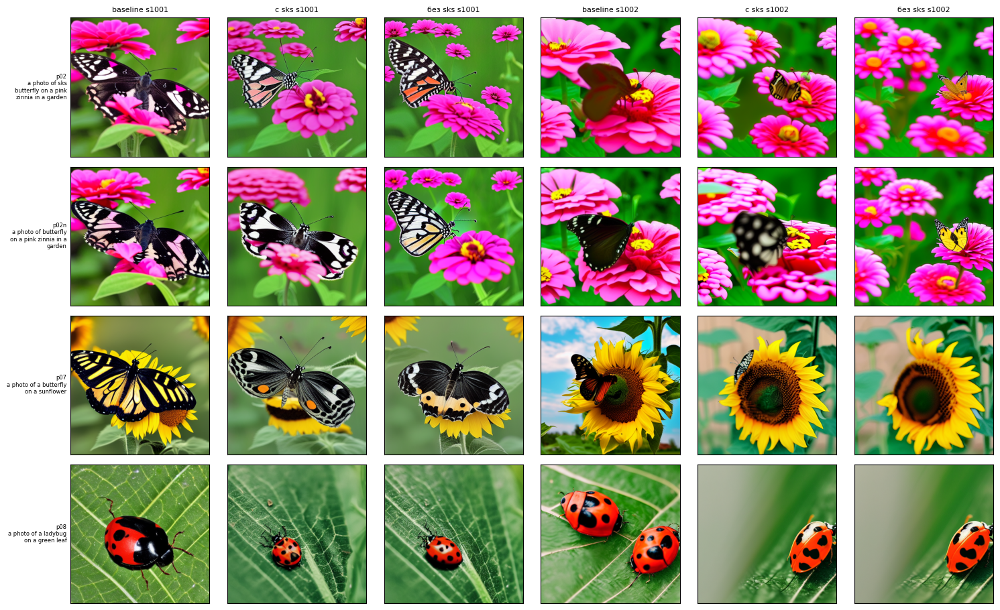

status=passed, изображений=168, результаты: /content/drive/MyDrive/lab13/artifacts/full_run/ablation


In [20]:
if 'ABL_RESULT' not in globals(): raise SystemExit('Сначала выполните ячейки 1 и 2 бонуса')
import pandas as pd
import torch.nn.functional as F
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from peft.tuners.lora import LoraLayer
from transformers import CLIPModel, CLIPProcessor
from huggingface_hub import HfApi

def lora_count(m): return sum(isinstance(x, LoraLayer) for x in m.modules())
def mad(a, b): return float(np.abs(a.astype(np.float32) - b.astype(np.float32)).mean())

last = str(S['checkpoint_updates'][-1])
DIRS = {'baseline': None, 'main': ADAPTERS[REF_NAME]['checkpoints'][last]['dir'],
        'abl': ABL_RESULT['checkpoints'][last]['dir']}
seeds = sorted({c['seed'] for c in EVAL_CASES})
active = {c['prompt_id'] for c in EVAL_CASES}
PR = [p for p in ABL_PROMPTS if p['pair'] in active]
PR_BY_ID = {p['id']: p for p in PR}
gen_dir = ABL_DIR / 'generations'
errors, imgs = [], {}

# ---------- 1. Генерация (протокол задания 3: те же шаги, guidance, разрешение, seeds) ----------
pipe = build_pipeline()
assert lora_count(pipe.unet) == 0
for model, d in DIRS.items():
    if d: pipe.load_lora_weights(d)
    if lora_count(pipe.unet) != (len(target_shapes) if d else 0): errors.append(f'{model}: неверное число LoRA-слоёв')
    (gen_dir / model).mkdir(parents=True, exist_ok=True)
    for pr in PR:
        for sd in seeds:
            im = generate_case(pipe, {'prompt': pr['text'], 'seed': sd})
            im.save(gen_dir / model / f"{pr['id']}_s{sd}.png")
            imgs[(model, pr['id'], sd)] = np.asarray(im.convert('RGB'))
    if d: pipe.unload_lora_weights()
del pipe; gc.collect(); torch.cuda.empty_cache()
if len(imgs) != 3 * len(PR) * len(seeds): errors.append('Сгенерированы не все изображения')
if 'BASELINE' in globals():    # baseline совпадает с заданием 3
    for c in EVAL_CASES[:4]:
        if c['case_id'] in BASELINE and (c['prompt_id'], c['seed']) and ('baseline', c['prompt_id'], c['seed']) in imgs:
            d = mad(np.asarray(Image.open(BASELINE[c['case_id']]).convert('RGB')), imgs[('baseline', c['prompt_id'], c['seed'])])
            if d > 1.5: errors.append(f"baseline не воспроизводит задание 3 ({c['case_id']}: {d:.2f})")

# ---------- 2. CLIP-метрики ----------
CLIP_ID = 'openai/clip-vit-base-patch32'
try: CLIP_REV = HfApi().model_info(CLIP_ID).sha
except Exception: CLIP_REV = None
clip = CLIPModel.from_pretrained(CLIP_ID, revision=CLIP_REV).to('cuda').eval()
clip_proc = CLIPProcessor.from_pretrained(CLIP_ID, revision=CLIP_REV)

@torch.no_grad()
def img_emb(arrs):
    out = []
    for i in range(0, len(arrs), 16):
        px = clip_proc.image_processor([Image.fromarray(a) for a in arrs[i:i + 16]], return_tensors='pt')['pixel_values'].to('cuda')
        out.append(F.normalize(clip.visual_projection(clip.vision_model(pixel_values=px).pooler_output).float(), dim=-1).cpu())
    return torch.cat(out)

@torch.no_grad()
def txt_emb(texts):
    tok = clip_proc.tokenizer(texts, padding=True, truncation=True, max_length=77, return_tensors='pt').to('cuda')
    return F.normalize(clip.text_projection(clip.text_model(**tok).pooler_output).float(), dim=-1).cpu()

train_arrs = []
for r in TRAIN_RECORDS:
    with Image.open(LORA_DATA / r['file_name']) as im:
        train_arrs.append(np.asarray(ImageOps.fit(im.convert('RGB'), (RESOLUTION, RESOLUTION), Image.LANCZOS)))
TRAIN_E = img_emb(train_arrs)
keys = list(imgs)
EMB = dict(zip(keys, img_emb([imgs[k] for k in keys])))
# CLIP text similarity: prompt без sks для всех моделей, чтобы не штрафовать baseline за бессмысленный токен
TXT = dict(zip([p['id'] for p in PR], txt_emb([strip_sks(p['text']) for p in PR])))
del clip; gc.collect(); torch.cuda.empty_cache()

rows = []
for (model, pid, sd), e in EMB.items():
    sims = e @ TRAIN_E.T; j = int(sims.argmax())
    rows.append({'model': model, 'pid': pid, 'pair': PR_BY_ID[pid]['pair'], 'kind': PR_BY_ID[pid]['kind'], 'seed': sd,
                 'clip_t': float(e @ TXT[pid]), 'nt': float(sims.max()), 'nt_file': TRAIN_RECORDS[j]['file_name'],
                 'shift_clip': float(1 - e @ EMB[('baseline', pid, sd)]),
                 'shift_pix': mad(imgs[(model, pid, sd)], imgs[('baseline', pid, sd)])})
df = pd.DataFrame(rows)
div = []
for (model, pid), g in df.groupby(['model', 'pid']):
    E = torch.stack([EMB[(model, pid, s)] for s in g.seed]); n = len(E)
    div.append({'model': model, 'pid': pid, 'kind': PR_BY_ID[pid]['kind'],
                'diversity': float((1 - E @ E.T)[~torch.eye(n, dtype=bool)].mean()) if n > 1 else float('nan')})
div = pd.DataFrame(div)
if not np.isfinite(df[['clip_t', 'nt', 'shift_clip', 'shift_pix']].to_numpy()).all(): errors.append('Нечисловые значения метрик')
if mad(imgs[('main', PR[0]['id'], seeds[0])], imgs[('abl', PR[0]['id'], seeds[0])]) <= 0: errors.append('main и abl дают одинаковые картинки')

# ---------- 3. Таблица ----------
order = {'baseline': 0, 'main': 1, 'abl': 2}
table = (df.groupby(['kind', 'model'])[['clip_t', 'nt', 'shift_clip', 'shift_pix']].mean()
         .join(div.groupby(['kind', 'model'])['diversity'].mean()).round(4)
         .reset_index().sort_values(['kind', 'model'], key=lambda s: s.map(order) if s.name == 'model' else s))
print(table.to_string(index=False))

# ---------- 4. Проверка гипотез: бутстрап по prompts ----------
def per_prompt(model, kind, col):
    return df[(df.model == model) & (df.kind == kind)].groupby('pair')[col].mean()

def boot(v, n=5000, seed=0):
    v = np.asarray(v, dtype=float); rng = np.random.default_rng(seed)
    m = v[rng.integers(0, len(v), (n, len(v)))].mean(1)
    lo, hi = np.percentile(m, [2.5, 97.5])
    verdict = ('smoke (n=1)' if len(v) < 2 else 'подтверждено' if lo > 0 else 'опровергнуто' if hi < 0 else 'не определено')
    return {'mean': float(v.mean()), 'ci95': [float(lo), float(hi)], 'n_prompts': len(v),
            'n_positive': int((v > 0).sum()), 'verdict': verdict}

d_eff = {m: per_prompt(m, 'with_sks', 'nt') - per_prompt(m, 'no_sks', 'nt') for m in order}
stats = {'H1_sks_effect_main_minus_abl': boot(d_eff['main'] - d_eff['abl']),
         'H2_shift_no_sks_abl_minus_main': boot(per_prompt('abl', 'no_sks', 'shift_clip') - per_prompt('main', 'no_sks', 'shift_clip')),
         'H2b_nearest_train_no_sks_abl_minus_main': boot(per_prompt('abl', 'no_sks', 'nt') - per_prompt('main', 'no_sks', 'nt')),
         'sks_effect_by_model_nearest_train': {m: float(d_eff[m].mean()) for m in order}}   # baseline = шумовой пол
for k, v in stats.items(): print(k, v)

# ---------- 5. Картинки и отчёт ----------
rows_fig = [x for x in ('p02', 'p02n', 'p07', 'p08') if x in PR_BY_ID] or [p['id'] for p in PR[:3]]
sfig = seeds[:2]
fig, axes = plt.subplots(len(rows_fig), 3 * len(sfig), figsize=(2.2 * 3 * len(sfig) + 2, 2.3 * len(rows_fig)), squeeze=False)
for i, pid in enumerate(rows_fig):
    for si, sd in enumerate(sfig):
        for mi, model in enumerate(order):
            ax = axes[i, si * 3 + mi]; ax.imshow(imgs[(model, pid, sd)]); ax.set_xticks([]); ax.set_yticks([])
            if i == 0: ax.set_title({'baseline': 'baseline', 'main': 'с sks', 'abl': 'без sks'}[model] + f' s{sd}', fontsize=8)
    axes[i, 0].set_ylabel(f'{pid}\n' + textwrap.fill(PR_BY_ID[pid]['text'], 22), rotation=0, ha='right', va='center', fontsize=6)
fig.tight_layout(); fig.savefig(ABL_DIR / 'bonus_grid.png', dpi=120, bbox_inches='tight'); plt.show()

table.to_csv(ABL_DIR / 'bonus_table.csv', index=False)
df.to_csv(ABL_DIR / 'bonus_measurements.csv', index=False)
report = {'status': 'passed' if not errors else 'failed', 'fast_dev_run': FAST_DEV_RUN,
          'hypothesis_sha256': hyp_sha, 'reference_config': REF_NAME, 'ablation_config': ABL_CFG['name'],
          'checkpoint_used': int(last), 'eval_seeds': seeds, 'n_prompts': len(PR), 'clip_model': CLIP_ID, 'clip_revision': CLIP_REV,
          'versions': VERSIONS, 'stats': stats, 'table': table.to_dict('records'), 'errors': errors}
(ABL_DIR / 'bonus_report.json').write_text(json.dumps(report, ensure_ascii=False, indent=2))
print(f"status={report['status']}, изображений={len(imgs)}, результаты: {ABL_DIR}")
assert not errors, 'Абляция не принята:\n' + '\n'.join(errors)

### Анализ результатов

В ходе работы было обучено и сравнено несколько LoRA-адаптеров для Stable Diffusion 1.5 с разными параметрами. Качество генерации оценивалось по трём основным показателям: соответствию изображения текстовому запросу, разнообразию результатов и сходству с обучающими изображениями.

По результатам сравнения **лучшие результаты показал адаптер с LoRA rank = 16**. Значение CLIP text similarity оказалось самым высоким — **0.2904** против 0.2852 у baseline.

Применение LoRA адаптера в помогло получать более различные изображения.

По сходству с обучающими изображениями самое низкое значение показал тот же адаптер - 0.842

Дополнительный эксперимент с токеном `sks` показал, что его использование влияет на поведение адаптера. Основная модель и модель без `sks` по-разному реагировали на изменение запросов. Полученные статистические результаты поддержали гипотезы о влиянии токена на сходство с обучающими изображениями и на отклонение от базовой модели без `sks`. При этом дополнительная проверка показала, что большее отклонение от baseline не обязательно означает большее запоминание обучающих изображений.

Общий вывод: LoRA позволила изменить поведение Stable Diffusion и повысить разнообразие генераций. Адаптер C показал наиболее сбалансированные результаты по соответствию запросам и разнообразию, а адаптер B — наибольшее сходство с обучающими изображениями. При этом нельзя однозначно назвать один адаптер лучшим по всем критериям: выбор зависит от того, что важнее — соответствие запросу, разнообразие или сохранение особенностей обучающей выборки. Результаты следует рассматривать как сравнительные, поскольку число тестовых запросов и генераций ограничено, а метрики CLIP дают лишь косвенную оценку качества.

## Требования к сдаче

Перед сдачей перезапустите ядро и выполните все ячейки по порядку в полном режиме. Приложите конфигурацию, версии библиотек, источники/лицензии данных и модели, checkpoints, таблицу измерений, изображения и краткий анализ ошибок. Для длительного обучения перенесите каталог `artifacts/` на Google Drive и возобновляйте обучение с последнего checkpoint; отсутствие GPU или данных нельзя заменять синтетическими метриками.